# TP Integrador – Análisis de Datos (CEIA FIUBA, 4B 2026)
## NYC Yellow Taxi – agosto 2026 · Análisis exploratorio y preparación de datos

**Autor:** Facundo · **Dataset:** [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) – Yellow Taxi, agosto 2026.
Se trabaja con **un mes** siguiendo la recomendación de la cátedra (para evitar volumen de procesamiento).

### Problema de ML planteado
| Elemento | Definición |
|---|---|
| Tipo | **Regresión** supervisada |
| Target | `fare_amount`: tarifa del taxímetro en USD (sin recargos ni propina) |
| Momento de predicción | Cuando el pasajero sube e indica el destino |
| Cliente / usuario | **Pasajero o aplicación de viajes** que necesita **cotizar el precio antes de viajar** |
| Uso futuro | Estimar la tarifa con datos conocidos *a priori* (origen, destino, fecha/hora, pasajeros, tipo de tarifa), como hacen hoy los viajes *Flex Fare* pedidos por app, cuyo precio se pacta de antemano |

**¿Por qué no el taxista como cliente?** Para el conductor, la tarifa de un viaje ya la calcula el taxímetro: predecirla le aporta poco.
Una versión orientada al taxista (por ejemplo, predecir el **ingreso por minuto** según zona y horario) queda como trabajo futuro.

**Datos:** la primera celda de código descarga los archivos desde la fuente oficial de la TLC y los guarda en `data/`.
Si ya existen ahí, usa la copia local y no descarga nada (ver README).

### Flujo de trabajo (según "Flujo de preparación de datos")
| Etapa | Secciones | Qué se hace |
|---|---|---|
| **EDA** | 1 a 11 | Solo se **observa y describe** el dataset completo: no se elimina, imputa ni transforma nada |
| **Limpieza básica y población** | 12 | Se eliminan errores imposibles y se define el alcance (reglas fijas, sin estadísticos) |
| **Wrangling** | 13 | Se enriquecen los datos fila por fila (zonas, hora, día, tipos) |
| **Split** | 14 | Train / test |
| **Transformaciones** (calculadas en train, aplicadas en train y test) | 15 a 21 | Nulos (15) → outliers (16) → crear features (17) → discretizar (18) → codificar (19) → escalar (20) → balanceo, no aplica (21) |
| **Reducción de dimensionalidad** | 22 y 23 | Selección de features (22) y extracción con PCA (23) |
| **Conclusiones** | 24 | Hallazgos, resultado y limitaciones |
| Anexo | — | Glosario de medidas estadísticas |

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import urllib.request

# ---- Datos: se descargan de la fuente oficial (NYC TLC) solo si no existe la copia local en data/ ----
# Página fuente: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
DATA_DIR = Path("data")
BASE_URL = "https://d37ci6vzurychx.cloudfront.net"
DATA_PARQUET = DATA_DIR / "yellow_tripdata_2026-08.parquet"   # viajes Yellow Taxi, agosto 2026 (~59 MB)
DATA_ZONES   = DATA_DIR / "taxi_zone_lookup.csv"              # tabla oficial de zonas TLC (ID → borough / zona)
FUENTES = {
    DATA_PARQUET: f"{BASE_URL}/trip-data/yellow_tripdata_2026-08.parquet",
    DATA_ZONES:   f"{BASE_URL}/misc/taxi_zone_lookup.csv",
}
DATA_DIR.mkdir(exist_ok=True)
for destino, url in FUENTES.items():
    if destino.exists():
        print(f"OK, copia local: {destino}")
    else:
        print(f"Descargando {url} ...")
        urllib.request.urlretrieve(url, destino)
        print(f"Guardado en {destino}")
FIG_DIR = Path("figures/eda"); FIG_DIR.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 40)
SEED = 42

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png")

OK, copia local: data/yellow_tripdata_2026-08.parquet
OK, copia local: data/taxi_zone_lookup.csv


---
# 1. Dimensiones y tipos de datos

In [2]:
df = pd.read_parquet(DATA_PARQUET)
zonas = pd.read_csv(DATA_ZONES)
COLS_ORIGINALES = list(df.columns)

print(f"Observaciones: {df.shape[0]:,}  |  Variables: {df.shape[1]}")
print(f"Memoria: {df.memory_usage(deep=True).sum()/1e6:,.0f} MB")
print(f"Período de pickup: {df['tpep_pickup_datetime'].min()}  →  {df['tpep_pickup_datetime'].max()}")
df.dtypes.to_frame("dtype")

Observaciones: 3,336,716  |  Variables: 21
Memoria: 529 MB
Período de pickup: 2009-01-01 14:39:49  →  2026-08-31 23:59:59


,dtype
VendorID,int32
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float64
trip_distance,float64
RatecodeID,float64
store_and_fwd_flag,str
PULocationID,int32
DOLocationID,int32
payment_type,int64


In [3]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,request_source
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.000,0.600,1.000,N,140,262,1,6.500,3.500,0.500,2.300,0.000,1.000,13.800,2.500,0.000,0.000,NaN
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.000,0.700,1.000,N,140,262,1,6.500,3.500,0.500,3.450,0.000,1.000,14.950,2.500,0.000,0.000,NaN
2,1,2026-08-01 00:54:51,2026-08-01 01:01:07,1.000,1.100,1.000,N,140,263,1,7.900,3.500,0.500,2.600,0.000,1.000,15.500,2.500,0.000,0.000,NaN
3,2,2026-08-01 00:27:35,2026-08-01 00:54:27,1.000,5.240,1.000,N,164,80,1,29.600,1.000,0.500,8.560,7.460,1.000,51.370,2.500,0.000,0.750,NaN
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.000,3.570,1.000,N,148,141,1,20.500,1.000,0.500,5.250,0.000,1.000,31.500,2.500,0.000,0.750,NaN


### Diccionario y tipo estadístico de cada variable
Fuente: *Data Dictionary – Yellow Taxi Trip Records*, NYC TLC (18/03/2025).

| # | Variable | Qué es | Tipo estadístico | Rol esperado (hipótesis, se confirma en el EDA) |
|---|---|---|---|---|
| 1 | `fare_amount` | Tarifa calculada por el taxímetro según tiempo y distancia, en USD. No incluye recargos, peajes ni propina. En los viajes con tarifa fija (JFK) o negociada, es el monto pactado | Numérica continua | **Target** |
| 2 | `VendorID` | Empresa proveedora del sistema del taxímetro que generó el registro: 1 Creative Mobile Technologies, 2 Curb Mobility, 6 Myle Technologies, 7 Helix | Categórica nominal (codificada con números) | Candidata a feature: se conoce al subir |
| 3 | `tpep_pickup_datetime` | Fecha y hora en que se activó el taxímetro (inicio del viaje) | Fecha/hora → de ella salen la hora (cíclica) y el día de la semana | Candidata a feature |
| 4 | `tpep_dropoff_datetime` | Fecha y hora en que se apagó el taxímetro (fin del viaje) | Fecha/hora | Candidata a excluir: *leakage* (junto con el pickup da la duración, que se conoce al final) |
| 5 | `passenger_count` | Cantidad de pasajeros; la carga el conductor a mano | Numérica discreta | Candidata a feature |
| 6 | `trip_distance` | Distancia recorrida en millas, medida por el taxímetro al terminar el viaje | Numérica continua | Candidata a excluir: *leakage* (no se conoce al subir) |
| 7 | `RatecodeID` | Tipo de tarifa vigente al terminar el viaje: 1 estándar, 2 JFK (tarifa fija ↔ Manhattan), 3 Newark, 4 Nassau/Westchester, 5 negociada, 6 grupal, 99 desconocido | Categórica nominal (codificada con números) | Candidata a feature (el destino se conoce al subir) |
| 8 | `store_and_fwd_flag` | Indica si el taxímetro perdió conexión con el servidor y guardó el viaje en memoria para enviarlo después (Y = sí, N = no) | Categórica binaria | Candidata a excluir: dato técnico de transmisión, sin relación con la tarifa |
| 9 | `PULocationID` | Zona TLC donde empezó el viaje (NYC dividida en 263 zonas + 2 "desconocidas") | Categórica nominal (codificada con números), alta cardinalidad | Candidata a feature |
| 10 | `DOLocationID` | Zona TLC donde terminó el viaje | Categórica nominal (codificada con números), alta cardinalidad | Candidata a feature (el pasajero dice el destino al subir) |
| 11 | `payment_type` | Medio de pago: 0 Flex Fare (tarifa pactada por app), 1 tarjeta, 2 efectivo, 3 sin cargo, 4 disputa, 5 desconocido, 6 anulado | Categórica nominal (codificada con números) | Candidata a excluir como feature: se conoce al pagar. Sirve para entender la población (Flex Fare no usa taxímetro) |
| 12 | `extra` | Recargos varios sumados a la tarifa, principalmente nocturno y de hora pico (el diccionario no los desglosa); toma pocos montos fijos | Numérica discreta | Candidata a excluir: no es parte del target; lo que la determina (la hora) ya entra como feature |
| 13 | `mta_tax` | Impuesto fijo de USD 0,50 por viaje destinado al transporte público (MTA) | Numérica discreta, casi constante | Candidata a excluir: no aporta variación |
| 14 | `tip_amount` | Propina; solo se registra si se paga con tarjeta (las propinas en efectivo no figuran) | Numérica continua | Candidata a excluir: *leakage* (se conoce al pagar) |
| 15 | `tolls_amount` | Peajes pagados durante el viaje (puentes, túneles) | Numérica continua | Candidata a excluir: *leakage* (depende del recorrido real) |
| 16 | `improvement_surcharge` | Recargo fijo de USD 1 por viaje, destinado a mejoras de la flota y accesibilidad | Numérica discreta, casi constante | Candidata a excluir: no aporta variación |
| 17 | `total_amount` | Total cobrado al pasajero: tarifa + recargos + peajes + propina con tarjeta | Numérica continua | Candidata a excluir: *leakage* (contiene al target) |
| 18 | `congestion_surcharge` | Recargo estatal de NY (USD 2,50) para viajes que circulan por la zona congestionada de Manhattan | Numérica discreta | Candidata a excluir: *leakage* (se confirma con el recorrido) |
| 19 | `Airport_fee` | Recargo (~USD 2) por **subir** al taxi en LaGuardia o JFK. No es la tarifa fija: esa la indica `RatecodeID = 2` | Numérica discreta | Candidata a excluir: redundante con la zona de origen |
| 20 | `cbd_congestion_fee` | Peaje por congestión (USD 0,75) para viajes que entran, salen o circulan por el centro de Manhattan (al sur de la calle 60); vigente desde el 05/01/2025 | Numérica discreta | Candidata a excluir: depende del recorrido |
| 21 | `request_source` | Origen del pedido del viaje. **No figura en el diccionario oficial**; los códigos HV0003 y HV0005 coinciden con las licencias de Uber y Lyft | Categórica nominal | A evaluar en el EDA |

La columna de rol es una **hipótesis** basada en el diccionario y en el momento de predicción; el rol definitivo de cada variable,
con la evidencia del EDA, está en la sección 11.

**Casos borde:** zonas, `RatecodeID`, `VendorID` y `payment_type` vienen como números pero son **categóricas**.
La hora es discreta pero **cíclica** (23 h está cerca de 0 h).

In [4]:
# Cardinalidad de cada variable (ayuda a confirmar el tipo)
df.nunique().to_frame("valores distintos").T

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,request_source
valores distintos,4,1698616,1699241,8,5169,6,2,261,261,5,12037,198,11,4466,1153,5,20411,6,8,3,6


---
# 2. Columnas auxiliares para explorar
Para poder **mirar** los datos se calculan algunas columnas auxiliares (no son todavía *features* del modelo;
la creación formal de features va en la etapa de transformaciones, después del split):
- `duracion_min` (dropoff − pickup), `hora` y `dia_semana` del pickup.
- Borough y nombre de zona de origen/destino, cruzando con la tabla oficial de zonas.

In [5]:
df["duracion_min"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
df["hora"] = df["tpep_pickup_datetime"].dt.hour
df["dia_semana"] = df["tpep_pickup_datetime"].dt.dayofweek          # 0 = lunes
z = zonas.set_index("LocationID")
for pref, col in [("PU", "PULocationID"), ("DO", "DOLocationID")]:
    df[f"{pref}_borough"]  = df[col].map(z["Borough"])
    df[f"{pref}_zona"]     = df[col].map(z["Zone"])
    df[f"{pref}_servicio"] = df[col].map(z["service_zone"])

# Muestra aleatoria fija SOLO para GRAFICAR (scatter, boxplots): con 3,3 M de puntos los gráficos quedan
# saturados e ilegibles y pueden colgar el kernel. Todos los estadísticos y tests se calculan sobre el total.
muestra = df.sample(200_000, random_state=SEED)
print(f"Muestra para gráficos: {len(muestra):,} viajes ({len(muestra)/len(df):.1%} del total)")

Muestra para gráficos: 200,000 viajes (6.0% del total)


**¿La muestra es representativa?** Se comparan algunos indicadores clave del total contra la muestra:

In [6]:
def indicadores(x):
    return pd.Series({"mediana fare_amount": x["fare_amount"].median(),
                      "Q1 fare_amount": x["fare_amount"].quantile(.25),
                      "Q3 fare_amount": x["fare_amount"].quantile(.75),
                      "mediana trip_distance": x["trip_distance"].median(),
                      "% Flex Fare (payment_type = 0)": (x["payment_type"] == 0).mean() * 100,
                      "% tarifa fija JFK (RatecodeID = 2)": (x["RatecodeID"] == 2).mean() * 100,
                      "% origen Manhattan": (x["PU_borough"] == "Manhattan").mean() * 100})
pd.DataFrame({"total": indicadores(df), "muestra": indicadores(muestra)})

,total,muestra
mediana fare_amount,15.600,15.600
Q1 fare_amount,10.000,10.000
Q3 fare_amount,26.100,26.100
mediana trip_distance,1.990,1.990
% Flex Fare (payment_type = 0),27.607,27.725
% tarifa fija JFK (RatecodeID = 2),2.458,2.457
% origen Manhattan,86.752,86.698


Los valores son prácticamente idénticos: la muestra aleatoria de 200.000 viajes reproduce la distribución del total,
por lo que los gráficos hechos con ella son representativos.

---
# 3. Análisis univariado del target: `fare_amount`
Estadística **clásica** (media, desvío) y **robusta** (mediana, media recortada, IQR, MAD), forma de la distribución
(asimetría, curtosis) y criterio de concentración: el IQR es "pequeño" (datos concentrados) si es < 20 % del rango.
Definición, fórmula y rango de cada medida: ver **Anexo – Glosario de medidas** al final del notebook.

In [7]:
def resumen(s):
    s = s.dropna()
    q1, q2, q3 = s.quantile([.25, .5, .75]); iqr = q3 - q1
    return pd.Series({
        "n": len(s), "media": s.mean(), "mediana": q2, "media_recortada_10%": stats.trim_mean(s, .10),
        "moda": s.mode().iloc[0], "desvío": s.std(), "IQR": iqr, "MAD": stats.median_abs_deviation(s),
        "mín": s.min(), "P1": s.quantile(.01), "P99": s.quantile(.99), "máx": s.max(),
        "asimetría": s.skew(), "curtosis_exceso": s.kurt(), "IQR / rango (%)": iqr / (s.max() - s.min()) * 100,
    })

resumen(df["fare_amount"]).to_frame("fare_amount")

,fare_amount
n,"3,336,716.000"
media,21.169
mediana,15.600
media_recortada_10%,17.979
moda,8.600
desvío,19.764
IQR,16.100
MAD,7.000
mín,"-1,849.600"
P1,3.000


In [8]:
f = df["fare_amount"]
print(f"Tarifas negativas: {(f < 0).sum():,}  |  iguales a 0: {(f == 0).sum():,}  |  mayores a 0 y menores a 3 USD: {((f > 0) & (f < 3)).sum():,}")
print(f"Tarifa exacta USD 70 (tarifa fija JFK): {(f == 70).sum():,} ({(f == 70).mean():.1%})")
print(f"Tarifas de la forma 3 + 0,70·n (bajada de bandera + saltos del taxímetro): {(f.mod(0.7).round(2) == 0.2).mean():.1%}")
print("\nValores más frecuentes:"); print(f.value_counts().head(8))

Tarifas negativas: 14,049  |  iguales a 0: 3,200  |  mayores a 0 y menores a 3 USD: 593
Tarifa exacta USD 70 (tarifa fija JFK): 82,054 (2.5%)
Tarifas de la forma 3 + 0,70·n (bajada de bandera + saltos del taxímetro): 67.2%

Valores más frecuentes:
fare_amount
8.600     107915
7.900     107124
9.300     107093
10.000    105030
7.200     101736
10.700     99616
11.400     95017
6.500      91002
Name: count, dtype: int64


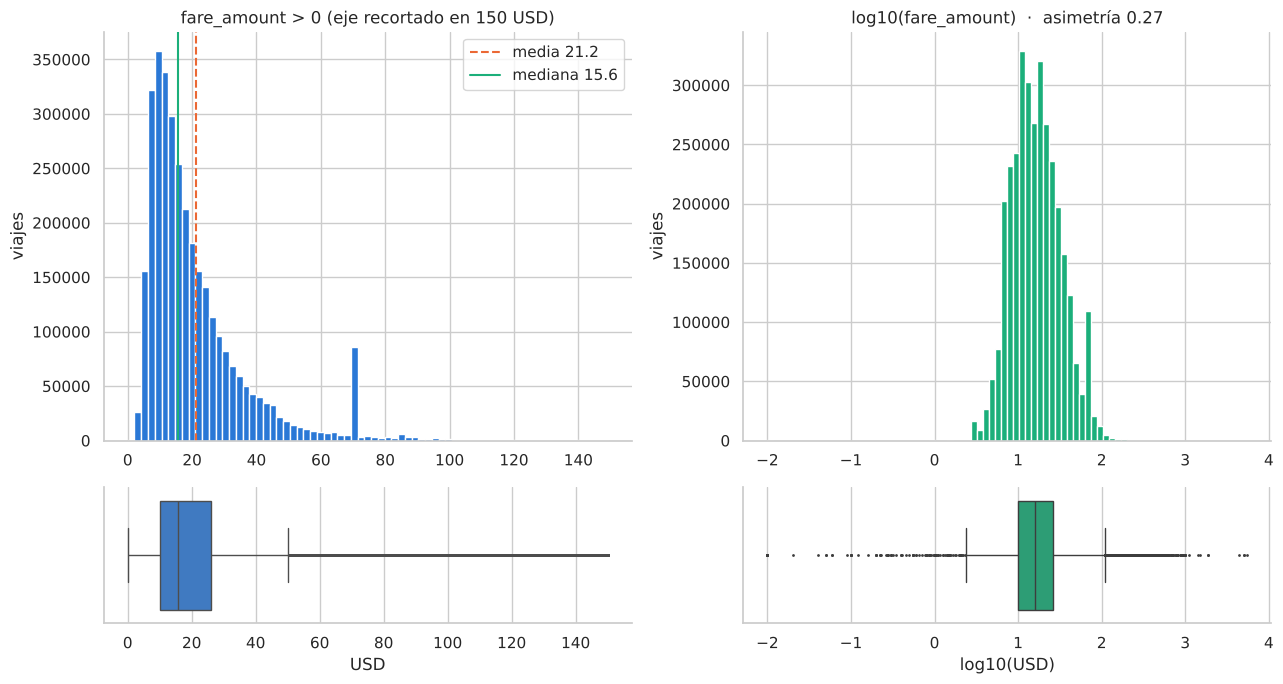

In [9]:
# Gráficos: el recorte (clip) y el log se usan SOLO para poder ver la distribución; los datos no se modifican
fig, axes = plt.subplots(2, 2, figsize=(13, 7), gridspec_kw={"height_ratios": [3, 1]})
fv = f[(f > 0)]
axes[0, 0].hist(fv.clip(upper=150), bins=np.arange(0, 151, 2.1), color=AZUL)
axes[0, 0].axvline(f.mean(), color=NARANJA, ls="--", label=f"media {f.mean():.1f}")
axes[0, 0].axvline(f.median(), color=VERDE, label=f"mediana {f.median():.1f}")
axes[0, 0].set(title="fare_amount > 0 (eje recortado en 150 USD)", ylabel="viajes"); axes[0, 0].legend()
sns.boxplot(x=fv.clip(upper=150), ax=axes[1, 0], color=AZUL, fliersize=1); axes[1, 0].set(xlabel="USD")

lf = np.log10(fv)
axes[0, 1].hist(lf, bins=80, color=VERDE)
axes[0, 1].set(title=f"log10(fare_amount)  ·  asimetría {lf.skew():.2f}", ylabel="viajes")
sns.boxplot(x=lf, ax=axes[1, 1], color=VERDE, fliersize=1); axes[1, 1].set(xlabel="log10(USD)")
plt.tight_layout(); guardar(fig, "01_target_distribucion"); plt.show()

**Qué se observa:**
- **Asimetría positiva fuerte** (cola a la derecha): moda < mediana < media. La media queda arrastrada por los viajes largos
  y de aeropuerto → el centro se describe mejor con la **mediana / media recortada**, y la dispersión con **IQR / MAD**.
- **Curtosis extremadamente alta (leptocúrtica):** colas pesadísimas. Unos pocos valores absurdos (−1.850 y +5.526 USD)
  disparan la asimetría y la curtosis clásicas, mientras que **mediana, IQR y MAD casi no se mueven**: ejemplo directo de por qué
  conviene la estadística robusta.
- **IQR / rango muy chico** (≪ 20 %): la mayoría de los viajes está concentrada en un rango estrecho de tarifas; el rango
  lo estiran unos pocos valores extremos.
- En escala log la distribución se ve mucho más simétrica
- El target es **escalonado**: el 67 % de las tarifas son USD 3 + 0,70·n (bajada de bandera + saltos del taxímetro); el resto
  son sobre todo viajes Flex Fare (precio pactado) y tarifas fijas. Pico aislado en **USD 70** (tarifa fija en el aeropuerto JFK, 2,5 % de los viajes).
- Aparecen fechas de **2009** en el pickup: errores de reloj del equipo (ver sección 10).
- Hay **valores imposibles**: tarifas negativas (reversiones/reembolsos) y tarifas por debajo de la bajada de bandera.

---
# 4. Análisis univariado de las demás numéricas

In [10]:
nums = ["passenger_count", "trip_distance", "duracion_min", "extra", "tolls_amount", "tip_amount",
        "congestion_surcharge", "Airport_fee", "cbd_congestion_fee", "mta_tax", "improvement_surcharge"]
pd.concat({c: resumen(df[c]) for c in nums}, axis=1).T

,n,media,mediana,media_recortada_10%,moda,desvío,IQR,MAD,mín,P1,P99,máx,asimetría,curtosis_exceso,IQR / rango (%)
passenger_count,"2,415,535.000",1.269,1.000,1.104,1.000,0.672,0.000,0.000,0.000,1.000,4.000,8.000,2.905,9.452,0.000
trip_distance,"3,336,716.000",4.904,1.990,2.658,0.000,420.551,3.140,1.180,0.000,0.000,19.640,"223,198.740",350.495,"133,049.052",0.001
duracion_min,"3,336,716.000",17.026,14.183,15.266,0.000,221.772,13.633,6.500,"-300,517.517",0.000,61.683,"8,373.667","-1,275.531","1,651,304.765",0.004
extra,"3,336,716.000",1.140,0.000,0.780,0.000,1.770,2.500,0.000,-7.500,0.000,7.000,23.250,1.806,3.948,8.130
tolls_amount,"3,336,716.000",0.604,0.000,0.000,0.000,2.345,0.000,0.000,-106.460,0.000,7.460,616.790,10.278,"1,477.490",0.000
tip_amount,"3,336,716.000",2.740,2.000,1.944,0.000,3.981,3.870,2.000,-90.000,0.000,17.440,444.440,4.366,98.747,0.724
congestion_surcharge,"2,415,535.000",2.255,2.500,2.500,2.500,0.782,0.000,0.000,-2.500,0.000,2.500,2.750,-3.150,9.523,0.000
Airport_fee,"2,415,535.000",0.198,0.000,0.000,0.000,0.626,0.000,0.000,-2.000,0.000,2.000,27.000,3.722,37.942,0.000
cbd_congestion_fee,"3,336,716.000",0.572,0.750,0.624,0.750,0.324,0.000,0.000,-0.750,0.000,0.750,0.750,-1.338,0.101,0.000
mta_tax,"3,336,716.000",0.489,0.500,0.500,0.500,0.088,0.000,0.000,-0.500,0.000,0.500,11.500,-6.176,305.671,0.000


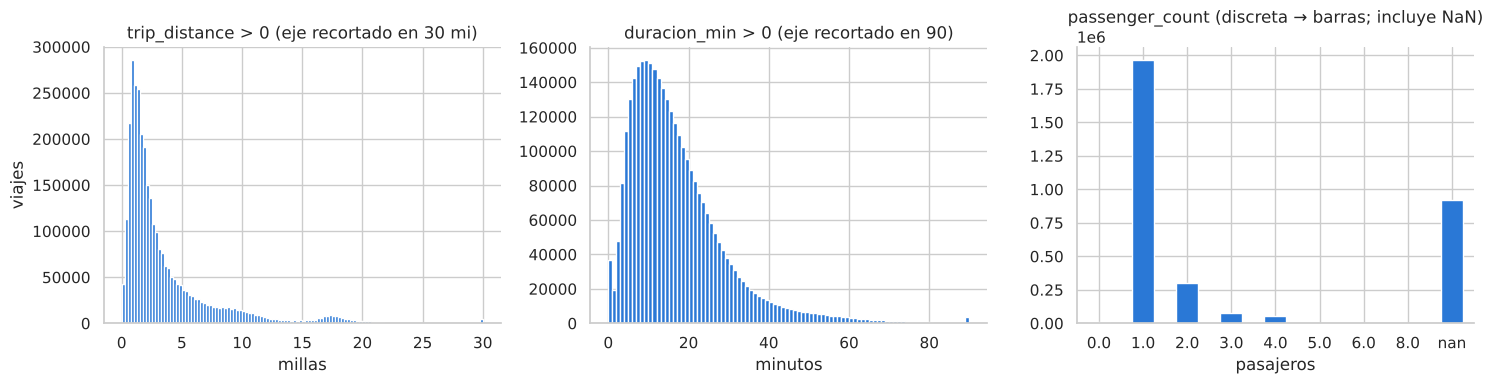

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
td = df["trip_distance"]; du = df["duracion_min"]
axes[0].hist(td[(td > 0)].clip(upper=30), bins=120, color=AZUL)
axes[0].set(title="trip_distance > 0 (eje recortado en 30 mi)", xlabel="millas", ylabel="viajes")
axes[1].hist(du[(du > 0)].clip(upper=90), bins=90, color=AZUL)
axes[1].set(title="duracion_min > 0 (eje recortado en 90)", xlabel="minutos")
df["passenger_count"].value_counts(dropna=False).sort_index().plot.bar(ax=axes[2], color=AZUL)
axes[2].set(title="passenger_count (discreta → barras; incluye NaN)", xlabel="pasajeros"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); guardar(fig, "02_numericas"); plt.show()

In [12]:
# Recargos de monto fijo: son numéricas, pero toman muy pocos valores → se miran como frecuencias
for c in ["extra", "congestion_surcharge", "Airport_fee", "cbd_congestion_fee", "mta_tax", "improvement_surcharge"]:
    vc = df[c].value_counts(normalize=True, dropna=False).mul(100).head(5).round(2)
    print(f"{c:24s}", dict(vc))

extra                    {0.0: np.float64(57.9), 1.0: np.float64(14.12), 2.5: np.float64(11.99), 3.25: np.float64(6.48), 5.0: np.float64(2.55)}
congestion_surcharge     {2.5: np.float64(65.63), nan: np.float64(27.61), 0.0: np.float64(6.42), -2.5: np.float64(0.34), 0.75: np.float64(0.01)}
Airport_fee              {0.0: np.float64(65.19), nan: np.float64(27.61), 2.0: np.float64(7.09), -2.0: np.float64(0.08), 7.0: np.float64(0.03)}
cbd_congestion_fee       {0.75: np.float64(76.52), 0.0: np.float64(23.19), -0.75: np.float64(0.29)}
mta_tax                  {0.5: np.float64(98.13), 0.0: np.float64(1.46), -0.5: np.float64(0.41), 1.24: np.float64(0.0), 4.75: np.float64(0.0)}
improvement_surcharge    {1.0: np.float64(99.31), -1.0: np.float64(0.43), 0.3: np.float64(0.18), 0.0: np.float64(0.08), 4.0: np.float64(0.0)}


**Qué se observa:**
- `trip_distance` y `duracion_min` repiten el patrón del target: asimetría positiva y colas largas. Además tienen **valores
  imposibles**: distancias de 0 y de cientos de miles de millas, duraciones negativas o de días.
- `passenger_count` está **muy concentrada en 1** (IQR = 0). El valor **0** no es posible en un viaje cobrado: es un
  **faltante disfrazado**.
- Los recargos son **casi constantes** (`mta_tax`, `improvement_surcharge`) o toman pocos montos fijos dominantes (p. ej. `extra`: 0; 1; 2,5; 3,25 USD); algunos tienen valores
  negativos (reversiones).

---
# 5. Análisis univariado de las categóricas
Concentración (moda y % de la moda), cardinalidad y diversidad con la **entropía de Shannon**
$H=-\sum p_i \log_2 p_i$ (normalizada: $H/\log_2 k$; cerca de 1 = equiprobables, cerca de 0 = una categoría domina).

In [13]:
def resumen_cat(s):
    p = s.value_counts(normalize=True, dropna=False); k = len(p)
    H = -(p * np.log2(p)).sum()
    return pd.Series({"cardinalidad": k, "moda": p.index[0], "% moda": p.iloc[0] * 100,
                      "entropía (bits)": H, "entropía normalizada": H / np.log2(k) if k > 1 else 0})

cats = ["VendorID", "RatecodeID", "payment_type", "store_and_fwd_flag", "request_source",
        "PU_borough", "DO_borough", "PU_servicio", "PULocationID", "DOLocationID"]
pd.DataFrame({c: resumen_cat(df[c]) for c in cats}).T

,cardinalidad,moda,% moda,entropía (bits),entropía normalizada
VendorID,4.000,2.000,81.232,0.778,0.389
RatecodeID,7.000,1.000,66.108,1.276,0.454
payment_type,5.000,1.000,61.501,1.350,0.581
store_and_fwd_flag,3,N,72.219,0.868,0.547
request_source,7.000,NaN,72.403,1.195,0.426
PU_borough,7,Manhattan,86.752,0.712,0.254
DO_borough,7,Manhattan,85.678,0.831,0.296
PU_servicio,5,Yellow Zone,83.216,0.835,0.359
PULocationID,261.000,132.000,4.573,5.947,0.741
DOLocationID,261.000,161.000,3.428,6.347,0.791


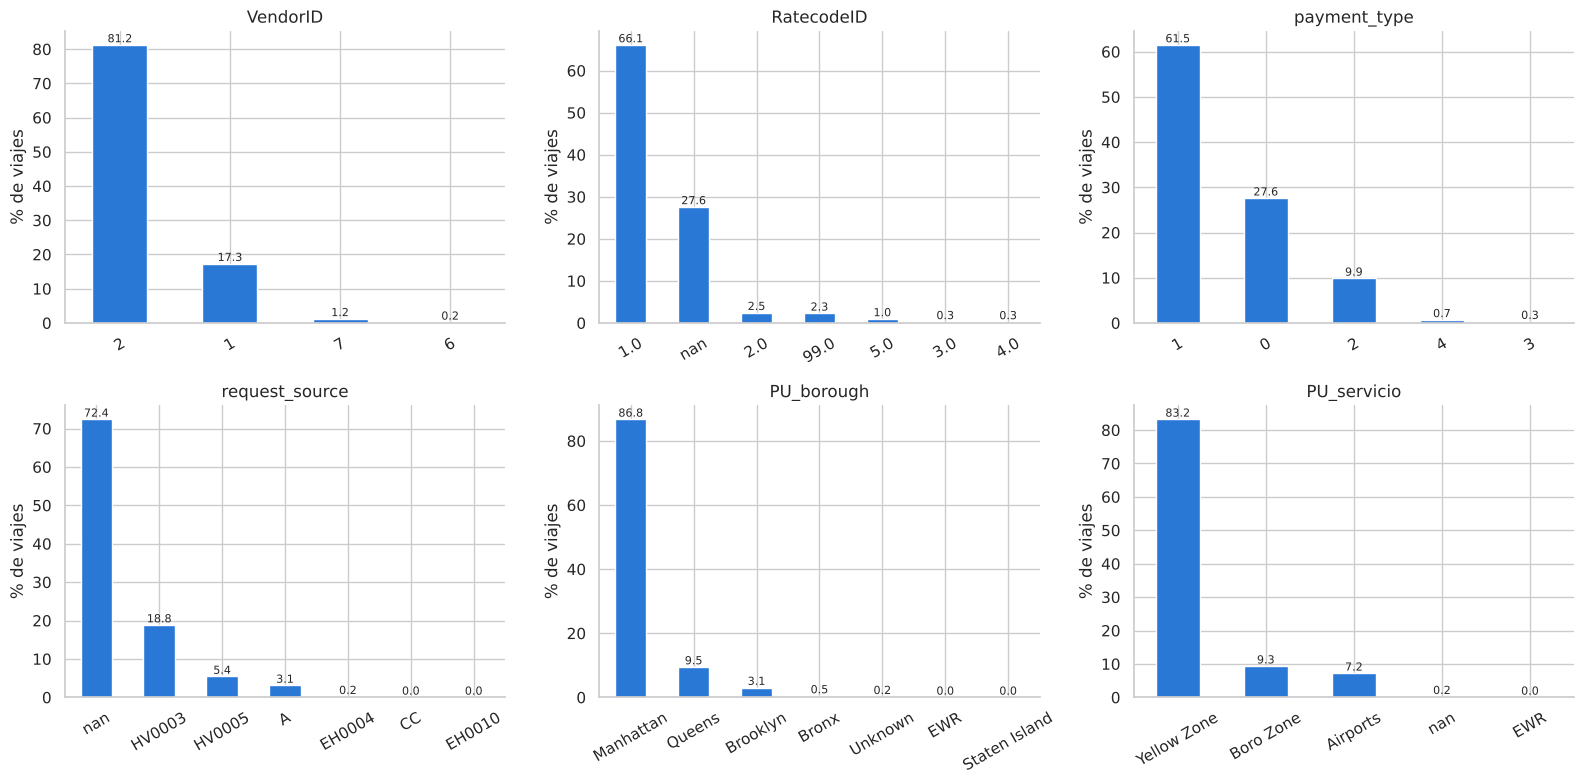

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, ["VendorID", "RatecodeID", "payment_type", "request_source", "PU_borough", "PU_servicio"]):
    vc = df[c].value_counts(dropna=False, normalize=True).mul(100)
    vc.index = vc.index.astype(str)
    vc.plot.bar(ax=ax, color=AZUL)
    ax.set(title=c, ylabel="% de viajes", xlabel=""); ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); guardar(fig, "03_categoricas"); plt.show()

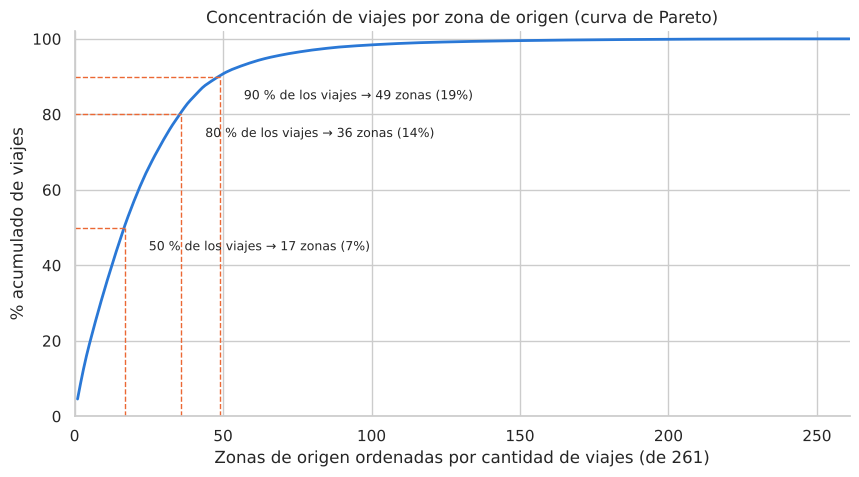

Zonas necesarias: 50 % → 17 · 80 % → 36 · 90 % → 49 (de 261)
Las 5 zonas con más viajes (%): {'JFK Airport': np.float64(4.6), 'Midtown Center': np.float64(4.1), 'Upper East Side South': np.float64(3.8), 'Penn Station/Madison Sq West': np.float64(3.5), 'Upper East Side North': np.float64(3.2)}


In [15]:
# Curva de Pareto: zonas de origen ordenadas de mayor a menor cantidad de viajes, y % acumulado de viajes
frec = df["PULocationID"].value_counts(normalize=True).mul(100)
acum = frec.cumsum().reset_index(drop=True)
acum.index = acum.index + 1                       # posición 1 = zona con más viajes
n_zonas = len(acum)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(acum.index, acum.values, color=AZUL, lw=2)
umbrales = {}
for p in [50, 80, 90]:
    k = int((acum < p).sum() + 1)                 # zonas necesarias para alcanzar p %
    umbrales[p] = k
    ax.hlines(p, 0, k, color=NARANJA, ls="--", lw=1)
    ax.vlines(k, 0, p, color=NARANJA, ls="--", lw=1)
    ax.annotate(f"{p} % de los viajes → {k} zonas ({k / n_zonas:.0%})", xy=(k, p),
                xytext=(k + 8, p - 6), fontsize=9)
ax.set(title="Concentración de viajes por zona de origen (curva de Pareto)",
       xlabel=f"Zonas de origen ordenadas por cantidad de viajes (de {n_zonas})",
       ylabel="% acumulado de viajes", xlim=(0, n_zonas), ylim=(0, 102))
guardar(fig, "04_pareto_zonas_origen"); plt.show()

print(f"Zonas necesarias: 50 % → {umbrales[50]} · 80 % → {umbrales[80]} · 90 % → {umbrales[90]} (de {n_zonas})")
top5 = df["PU_zona"].value_counts(normalize=True).mul(100).head(5).round(1)
print("Las 5 zonas con más viajes (%):", dict(top5))

**Qué se observa:**
- Variables **muy concentradas** (entropía normalizada baja): borough de origen y destino (Manhattan ≈ 86–87 %),
  `VendorID` (un proveedor tiene el 81 %), `RatecodeID` (domina la tarifa estándar).
- Las zonas tienen **alta cardinalidad** (261 de origen) pero están muy concentradas (patrón de Pareto): **36 zonas (14 %)
  reúnen el 80 % de los viajes**, principalmente aeropuerto JFK, Midtown y Upper East Side. Las restantes ~225 zonas, con pocos
  viajes cada una, son candidatas a agruparse (p. ej. por borough o en una categoría "otras") en la etapa de codificación.
- **27,6 % de los viajes son Flex Fare** (`payment_type = 0`): tarifa pactada por app, no medida por el taxímetro.
- `RatecodeID = 99` ("desconocido") y la categoría NaN aparecen como valores propios → se analizan en faltantes (sección 9).
- **2,5 % de los viajes tienen tarifa fija JFK** (`RatecodeID = 2`, USD 70): su precio no requiere predicción.
  Queda como **decisión para la preparación**: excluirlos del alcance o dejarlos y que `RatecodeID` lo capture.

---
# 6. Patrón temporal

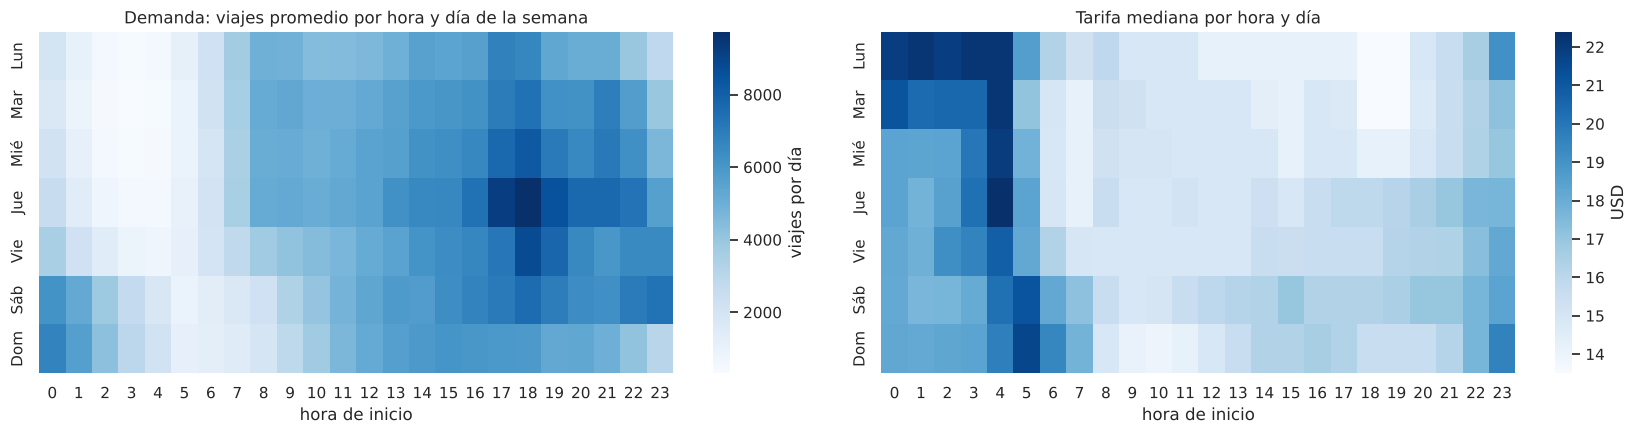

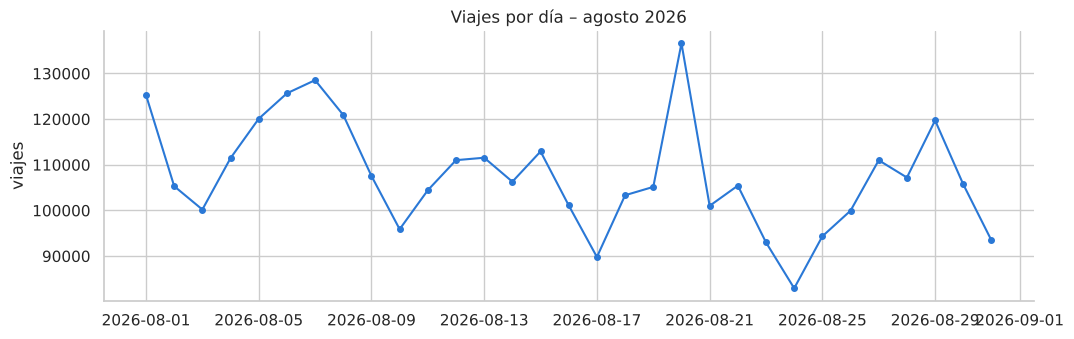

In [16]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ago = df[df["tpep_pickup_datetime"].dt.month.eq(8) & df["tpep_pickup_datetime"].dt.year.eq(2026)]
n_dias = ago.groupby("dia_semana")["tpep_pickup_datetime"].apply(lambda s: s.dt.date.nunique())
viajes = ago.pivot_table(index="dia_semana", columns="hora", values="fare_amount", aggfunc="size").div(n_dias, axis=0)
mediana = ago.pivot_table(index="dia_semana", columns="hora", values="fare_amount", aggfunc="median")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
sns.heatmap(viajes, cmap="Blues", ax=axes[0], cbar_kws={"label": "viajes por día"}, yticklabels=dias)
axes[0].set(title="Demanda: viajes promedio por hora y día de la semana", xlabel="hora de inicio", ylabel="")
sns.heatmap(mediana, cmap="Blues", ax=axes[1], cbar_kws={"label": "USD"}, yticklabels=dias)
axes[1].set(title="Tarifa mediana por hora y día", xlabel="hora de inicio", ylabel="")
plt.tight_layout(); guardar(fig, "05_temporal_heatmap"); plt.show()

diario = ago.groupby(ago["tpep_pickup_datetime"].dt.date).size()
fig, ax = plt.subplots(figsize=(12, 3.5))
diario.plot(ax=ax, color=AZUL, marker="o", ms=4)
ax.set(title="Viajes por día – agosto 2026", ylabel="viajes", xlabel="")
guardar(fig, "06_viajes_por_dia"); plt.show()

**Qué se observa:** la demanda se concentra en la tarde de los días hábiles (pico 17–19 h) y en la noche del fin de semana;
la madrugada casi no tiene viajes. La tarifa mediana sube de madrugada (hay más viajes largos, p. ej. a aeropuertos),
pero la variación es moderada. A lo largo del mes se repite un **ciclo semanal**, sin tendencia marcada.

---
# 7. Análisis bivariado: relación de cada variable con el target
### 7.1 Numérica – numérica: Pearson, Spearman y Kendall
Pearson mide relación **lineal** (asume normalidad, sensible a outliers); Spearman y Kendall miden relación **monótona**
basada en rangos (robustos). Se calculan sobre el **total** de viajes con dato en ambas variables. Rangos y umbrales de interpretación: ver **Anexo – Glosario de medidas**.

**Nota sobre el costo de Kendall:** por definición compara **todos los pares** de observaciones (concordantes vs discordantes):
con n = 3.336.716 viajes son n(n−1)/2 ≈ **5,57 × 10¹² pares** (5,57 billones), inviable de recorrer uno por uno.
`scipy` no lo hace así: usa un algoritmo basado en ordenamiento (Knight, 1966) de orden n·log(n), que resuelve el total
en alrededor de un segundo.

In [17]:
filas = []
for c in ["trip_distance", "duracion_min", "passenger_count", "hora"]:
    m = df[[c, "fare_amount"]].dropna()          # passenger_count tiene NaN (bloque Flex Fare)
    filas.append({"variable": c, "n": len(m),
                  "Pearson": stats.pearsonr(m[c], m["fare_amount"])[0],
                  "Spearman": stats.spearmanr(m[c], m["fare_amount"])[0],
                  "Kendall τ": stats.kendalltau(m[c], m["fare_amount"])[0]})
pd.DataFrame(filas).set_index("variable")

,n,Pearson,Spearman,Kendall τ
variable,,,,
trip_distance,3336716,0.009,0.788,0.674
duracion_min,3336716,0.039,0.866,0.747
passenger_count,2415535,0.101,0.089,0.072
hora,3336716,-0.006,0.001,0.001


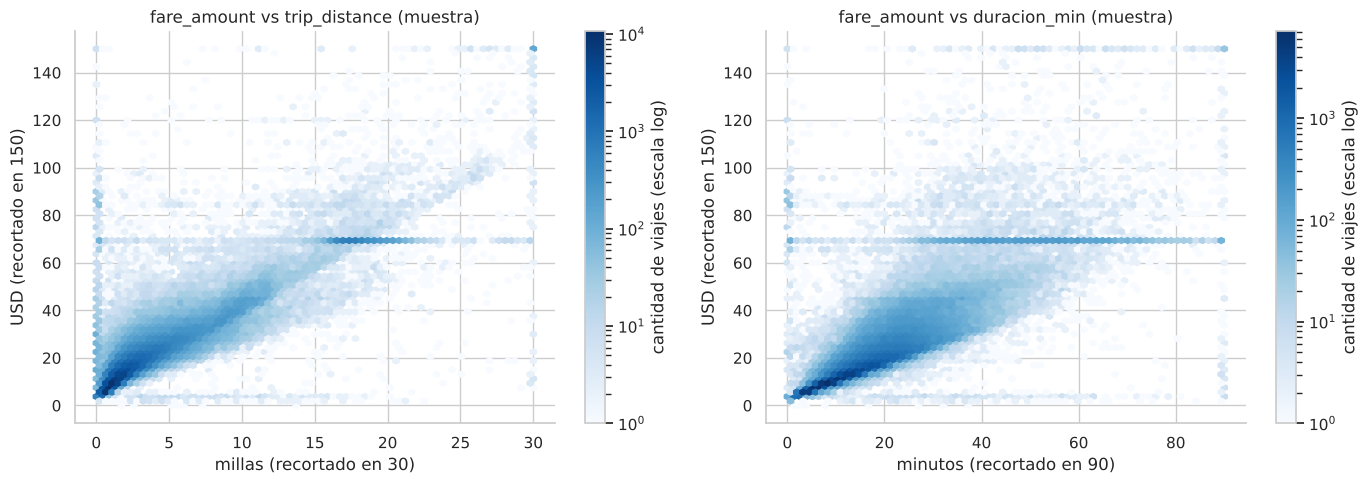

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
v = muestra[(muestra["fare_amount"] > 0) & (muestra["trip_distance"] > 0) & (muestra["duracion_min"] > 0)]
for ax, c, lab in [(axes[0], "trip_distance", "millas (recortado en 30)"), (axes[1], "duracion_min", "minutos (recortado en 90)")]:
    hb = ax.hexbin(v[c].clip(upper=30 if c == "trip_distance" else 90), v["fare_amount"].clip(upper=150),
                   gridsize=70, bins="log", cmap="Blues", mincnt=1)
    ax.set(title=f"fare_amount vs {c} (muestra)", xlabel=lab, ylabel="USD (recortado en 150)")
    fig.colorbar(hb, ax=ax, label="cantidad de viajes (escala log)")
plt.tight_layout(); guardar(fig, "07_scatter_target"); plt.show()

**Qué se observa:** relación **monótona y casi lineal** entre distancia y tarifa: el taxímetro cobra por milla.
Sin embargo, sobre el total de viajes **Pearson da ≈ 0,01 para la distancia y ≈ 0,04 para la duración, mientras Spearman da
0,79 y 0,87**: la relación es fuerte, pero unos pocos valores absurdos (distancias de 223.000 millas, duraciones negativas
o de días) anulan a Pearson. Es un ejemplo claro de por qué Pearson no es robusto a outliers y Spearman/Kendall sí. Aparece una
**banda horizontal en USD 70** (tarifa fija JFK, no depende de la distancia). Distancia y duración son los mejores
predictores... pero **no se conocen al subir** (*leakage*). Pasajeros y hora casi no se relacionan con la tarifa.

### 7.2 Categórica – numérica: Eta² (η²) y test ANOVA
η² = proporción de la varianza del target explicada por la categoría (0,06 moderado · 0,14 fuerte).
La significancia se evalúa con el **test ANOVA** (H₀: la media del target es igual en todos los grupos).

**Supuestos del ANOVA:** independencia de las observaciones, normalidad del target en cada grupo y homogeneidad de varianzas.
En este dataset **la normalidad y la homogeneidad de varianzas no se cumplen** (el target es muy asimétrico, sección 3,
y su dispersión cambia mucho según el grupo, ver los boxplots más abajo). Por eso el p-valor del ANOVA se toma **solo como
referencia**, y la conclusión se apoya en el **tamaño del efecto (η²)**, que no depende de esos supuestos para describir
qué proporción de la variabilidad explica cada categoría. η² y ANOVA salen de la misma descomposición de la varianza
(SS entre grupos / SS total).

In [19]:
def eta2(cat, y):
    d = pd.DataFrame({"c": cat, "y": y}).dropna()
    mu = d["y"].mean(); ss_tot = ((d["y"] - mu) ** 2).sum()
    ss_ent = d.groupby("c")["y"].agg(lambda g: len(g) * (g.mean() - mu) ** 2).sum()
    return ss_ent / ss_tot

def anova_p(cat, y):
    g = [x.values for _, x in pd.DataFrame({"c": cat, "y": y}).dropna().groupby("c")["y"] if len(x) > 1]
    return stats.f_oneway(*g).pvalue if len(g) > 1 else np.nan

cat_t = ["PULocationID", "DOLocationID", "PU_borough", "DO_borough", "PU_servicio", "RatecodeID",
         "payment_type", "VendorID", "request_source", "hora", "dia_semana"]
asoc = pd.DataFrame({"η²": [eta2(df[c], df["fare_amount"]) for c in cat_t],
                     "p-valor ANOVA (referencia)": [anova_p(df[c], df["fare_amount"]) for c in cat_t]},
                    index=cat_t).sort_values("η²", ascending=False)
asoc["efecto"] = pd.cut(asoc["η²"], [-1, .01, .06, .14, 2], labels=["despreciable", "débil", "moderado", "fuerte"])
asoc

,η²,p-valor ANOVA (referencia),efecto
RatecodeID,0.361,0.000,fuerte
PULocationID,0.276,0.000,fuerte
DOLocationID,0.262,0.000,fuerte
PU_servicio,0.246,0.000,fuerte
PU_borough,0.222,0.000,fuerte
DO_borough,0.192,0.000,fuerte
payment_type,0.021,0.000,débil
VendorID,0.008,0.000,despreciable
hora,0.002,0.000,despreciable
dia_semana,0.001,0.000,despreciable


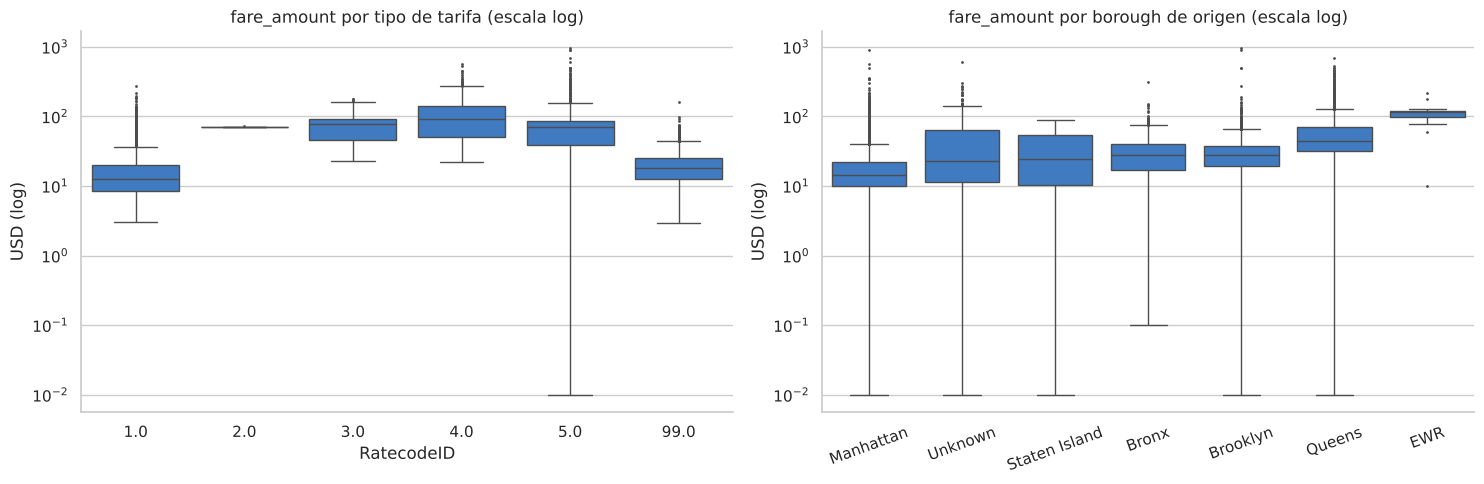

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
v = muestra[muestra["fare_amount"] > 0]
orden_rc = sorted(v["RatecodeID"].dropna().unique())
sns.boxplot(data=v, x="RatecodeID", y="fare_amount", order=orden_rc, ax=axes[0], color=AZUL, fliersize=1)
axes[0].set(yscale="log", title="fare_amount por tipo de tarifa (escala log)", ylabel="USD (log)")
orden_b = v.groupby("PU_borough")["fare_amount"].median().sort_values().index
sns.boxplot(data=v, x="PU_borough", y="fare_amount", order=orden_b, ax=axes[1], color=AZUL, fliersize=1)
axes[1].set(yscale="log", title="fare_amount por borough de origen (escala log)", ylabel="USD (log)", xlabel="")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); guardar(fig, "08_boxplots_target"); plt.show()

**Qué se observa:** con millones de datos **todos los tests dan p ≈ 0** (significativos), pero el **tamaño del efecto (η²)**
muestra lo que importa: las **zonas de origen/destino** y el **tipo de tarifa** explican una parte importante de la variación
de la tarifa (η² entre 0,19 y 0,36: efecto fuerte); proveedor, día y hora aportan muy poco. *Significancia estadística no es lo mismo que magnitud del efecto.*

### 7.3 Resumen: las 20 variables contra el target (verificación del rol hipotético)
Se mide la asociación de **cada una** de las 20 variables con `fare_amount`, con la medida que corresponde a su tipo:
**Spearman** para las numéricas (robusto, relación monótona) y **η²** para las categóricas. Cada variable se calcula sobre las
filas con dato (n); en `store_and_fwd_flag` y `request_source` el vacío es estructural y se toma como una categoría más. Para las fechas se usan sus derivadas: la hora y el día para el pickup, la duración para el dropoff.

**Tipo de análisis:** como el target es **numérico continuo**, cada cruce es **numérica – numérica** (se mide con Spearman)
o **categórica – numérica** (se mide con η²). No aparecen cruces categórica – categórica: esos corresponderían a un target
categórico; las relaciones categórica – categórica *entre features* se analizan en la sección 8 (V de Cramér).
`store_and_fwd_flag` es binaria, pero con el vacío estructural tiene 3 categorías: por eso se usa η² y no punto-biserial.
Las fechas se analizan a través de sus derivadas (hora y día → categóricas; duración → numérica).

Umbrales usados: η² → < 0,01 despreciable · 0,01–0,06 débil · 0,06–0,14 moderado · ≥ 0,14 fuerte.
|ρ| (convención) → < 0,1 despreciable · 0,1–0,3 débil · 0,3–0,7 moderada · ≥ 0,7 fuerte.

In [21]:
def lectura_rho(r):
    r = abs(r)
    return "despreciable" if r < .1 else "débil" if r < .3 else "moderada" if r < .7 else "fuerte"

def lectura_eta(e):
    return "despreciable" if e < .01 else "débil" if e < .06 else "moderado" if e < .14 else "fuerte"

def con_spearman(col):
    m = df[[col, "fare_amount"]].dropna()
    r = stats.spearmanr(m[col], m["fare_amount"])[0]
    return "Spearman ρ", round(r, 3), len(m), lectura_rho(r)

def con_eta(col, nan_como_categoria=False):
    if nan_como_categoria:   # cuando el vacío ES la información (faltante estructural)
        c = df[col].astype(object).where(df[col].notna(), "vacío")
        return "η²", round(eta2(c, df["fare_amount"]), 3), len(df), lectura_eta(eta2(c, df["fare_amount"]))
    n = df[col].notna().sum()
    e = eta2(df[col], df["fare_amount"])     # eta2 descarta los NaN
    return "η²", round(e, 3), n, lectura_eta(e)

# (variable, columna usada para medir, tipo de medida, ¿se conoce al subir?, rol hipotético de la sección 1)
variables = [
    ("VendorID", "Categórica nominal",              "VendorID",             "eta", "Sí",            "Candidata a feature"),
    ("tpep_pickup_datetime", "Fecha → hora (categórica cíclica)",  "hora",                 "eta", "Sí",            "Candidata a feature"),
    ("tpep_dropoff_datetime", "Fecha → duración (numérica continua)", "duracion_min",         "rho", "No",            "Candidata a excluir (leakage)"),
    ("passenger_count", "Numérica discreta",       "passenger_count",      "rho", "Sí",            "Candidata a feature"),
    ("trip_distance", "Numérica continua",         "trip_distance",        "rho", "No",            "Candidata a excluir (leakage)"),
    ("RatecodeID", "Categórica nominal",            "RatecodeID",           "eta", "Sí",            "Candidata a feature"),
    ("store_and_fwd_flag", "Categórica binaria (+ vacío)",    "store_and_fwd_flag",   "eta", "No aplica",     "Candidata a excluir (técnica)"),
    ("PULocationID", "Categórica nominal (alta cardinalidad)",          "PULocationID",         "eta", "Sí",            "Candidata a feature"),
    ("DOLocationID", "Categórica nominal (alta cardinalidad)",          "DOLocationID",         "eta", "Sí",            "Candidata a feature"),
    ("payment_type", "Categórica nominal",          "payment_type",         "eta", "No",            "Candidata a excluir como feature"),
    ("extra", "Numérica discreta (montos fijos)",                 "extra",                "rho", "Parcial (hora)", "Candidata a excluir"),
    ("mta_tax", "Numérica discreta (montos fijos)",               "mta_tax",              "rho", "Sí (fijo)",     "Candidata a excluir (casi constante)"),
    ("tip_amount", "Numérica continua",            "tip_amount",           "rho", "No",            "Candidata a excluir (leakage)"),
    ("tolls_amount", "Numérica continua",          "tolls_amount",         "rho", "No",            "Candidata a excluir (leakage)"),
    ("improvement_surcharge", "Numérica discreta (montos fijos)", "improvement_surcharge","rho", "Sí (fijo)",     "Candidata a excluir (casi constante)"),
    ("total_amount", "Numérica continua",          "total_amount",         "rho", "No",            "Candidata a excluir (leakage)"),
    ("congestion_surcharge", "Numérica discreta (montos fijos)",  "congestion_surcharge", "rho", "No",            "Candidata a excluir (leakage)"),
    ("Airport_fee", "Numérica discreta (montos fijos)",           "Airport_fee",          "rho", "Sí",            "Candidata a excluir (redundante)"),
    ("cbd_congestion_fee", "Numérica discreta (montos fijos)",    "cbd_congestion_fee",   "rho", "No",            "Candidata a excluir"),
    ("request_source", "Categórica nominal (+ vacío)",        "request_source",       "eta", "Solo app",      "A evaluar"),
]
filas = []
for var, tipo_var, col, tipo, al_subir, hip in variables:
    if tipo == "rho":
        medida, valor, n, lect = con_spearman(col)
    else:
        medida, valor, n, lect = con_eta(col, nan_como_categoria=col in ["store_and_fwd_flag", "request_source"])
    analisis = "Numérica – numérica" if tipo == "rho" else "Categórica – numérica"
    filas.append({"variable": var, "tipo de variable": tipo_var, "medida sobre": col,
                  "tipo de análisis (variable – target)": analisis, "medida": medida, "valor": valor, "n": n,
                  "asociación": lect, "¿se conoce al subir?": al_subir, "rol hipotético": hip})
# el pickup aporta también el día de la semana
dia = eta2(df["dia_semana"], df["fare_amount"])
filas.insert(2, {"variable": "tpep_pickup_datetime", "tipo de variable": "Fecha → día (categórica ordinal cíclica)",
                 "medida sobre": "dia_semana", "tipo de análisis (variable – target)": "Categórica – numérica",
                 "medida": "η²", "valor": round(dia, 3),
                 "n": len(df), "asociación": lectura_eta(dia), "¿se conoce al subir?": "Sí", "rol hipotético": "Candidata a feature"})
resumen_20 = pd.DataFrame(filas)
resumen_20

,variable,tipo de variable,medida sobre,tipo de análisis (variable – target),medida,valor,n,asociación,¿se conoce al subir?,rol hipotético
0,VendorID,Categórica nominal,VendorID,Categórica – numérica,η²,0.008,3336716,despreciable,Sí,Candidata a feature
1,tpep_pickup_datetime,Fecha → hora (categórica cíclica),hora,Categórica – numérica,η²,0.002,3336716,despreciable,Sí,Candidata a feature
2,tpep_pickup_datetime,Fecha → día (categórica ordinal cíclica),dia_semana,Categórica – numérica,η²,0.001,3336716,despreciable,Sí,Candidata a feature
3,tpep_dropoff_datetime,Fecha → duración (numérica continua),duracion_min,Numérica – numérica,Spearman ρ,0.866,3336716,fuerte,No,Candidata a excluir (leakage)
4,passenger_count,Numérica discreta,passenger_count,Numérica – numérica,Spearman ρ,0.089,2415535,despreciable,Sí,Candidata a feature
5,trip_distance,Numérica continua,trip_distance,Numérica – numérica,Spearman ρ,0.788,3336716,fuerte,No,Candidata a excluir (leakage)
6,RatecodeID,Categórica nominal,RatecodeID,Categórica – numérica,η²,0.361,2415535,fuerte,Sí,Candidata a feature
7,store_and_fwd_flag,Categórica binaria (+ vacío),store_and_fwd_flag,Categórica – numérica,η²,0.015,3336716,débil,No aplica,Candidata a excluir (técnica)
8,PULocationID,Categórica nominal (alta cardinalidad),PULocationID,Categórica – numérica,η²,0.276,3336716,fuerte,Sí,Candidata a feature
9,DOLocationID,Categórica nominal (alta cardinalidad),DOLocationID,Categórica – numérica,η²,0.262,3336716,fuerte,Sí,Candidata a feature


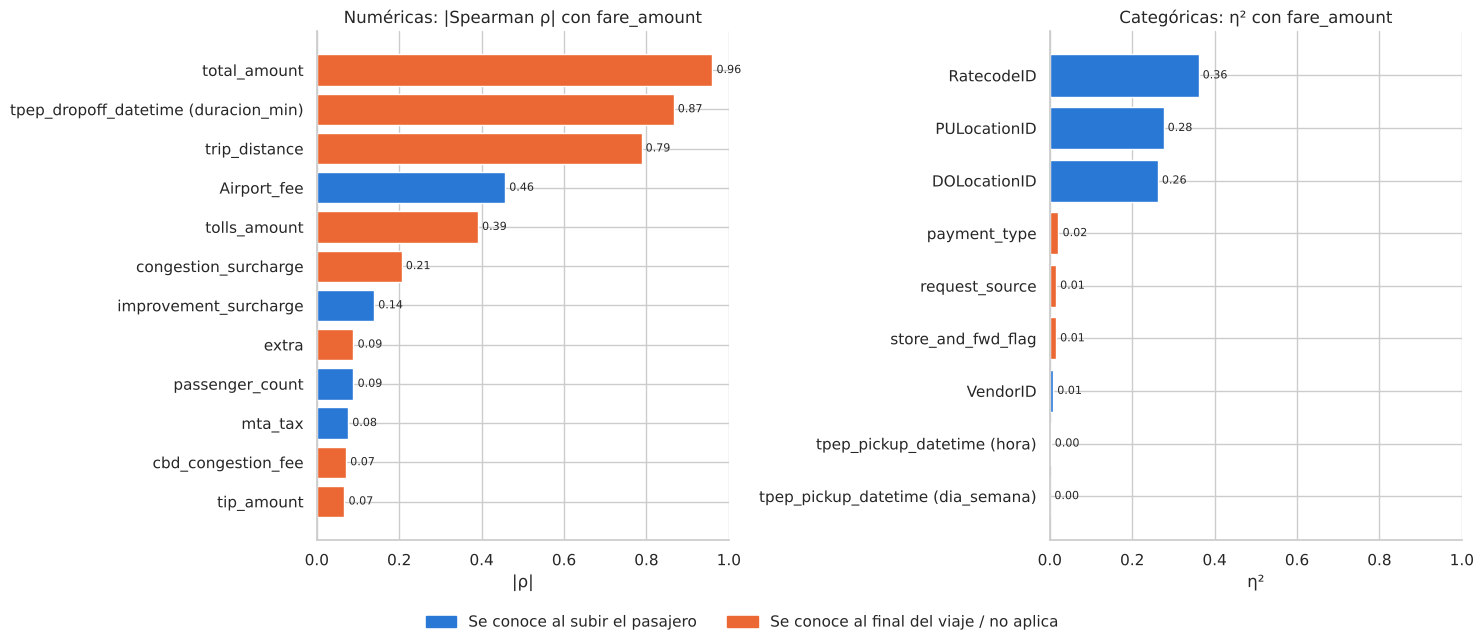

In [22]:
# Gráfico: fuerza de asociación con el target, coloreada según si la variable se conoce al subir el pasajero
color = resumen_20["¿se conoce al subir?"].map(lambda x: AZUL if x.startswith("Sí") else NARANJA)
etiqueta = resumen_20.apply(lambda r: r["variable"] if r["variable"] == r["medida sobre"]
                            else f'{r["variable"]} ({r["medida sobre"]})', axis=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, medida, titulo in [(axes[0], "Spearman ρ", "Numéricas: |Spearman ρ| con fare_amount"),
                           (axes[1], "η²", "Categóricas: η² con fare_amount")]:
    sel = resumen_20["medida"] == medida
    d = resumen_20[sel].assign(v=resumen_20.loc[sel, "valor"].abs(), et=etiqueta[sel], c=color[sel]).sort_values("v")
    ax.barh(d["et"], d["v"], color=d["c"])
    ax.set(title=titulo, xlabel="|ρ|" if medida.startswith("Spearman") else "η²", xlim=(0, 1))
    for y, v in enumerate(d["v"]):
        ax.text(v + .01, y, f"{v:.2f}", va="center", fontsize=8)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=AZUL, label="Se conoce al subir el pasajero"),
                    Patch(color=NARANJA, label="Se conoce al final del viaje / no aplica")],
           loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, .05, 1, 1)); guardar(fig, "08b_asociacion_20_variables"); plt.show()

In [23]:
# Evidencia de redundancia: ¿el recargo de aeropuerto es lo mismo que subir en JFK (132) o LaGuardia (138)?
con_fee = df["Airport_fee"] > 0
en_aerop = df["PULocationID"].isin([132, 138])
print(f"Viajes con Airport_fee > 0 que salen de JFK/LaGuardia: {en_aerop[con_fee].mean():.1%}")
print(f"Viajes que salen de JFK/LaGuardia con Airport_fee > 0 (sin contar Flex Fare): "
      f"{con_fee[en_aerop & (df['payment_type'] != 0)].mean():.1%}")

Viajes con Airport_fee > 0 que salen de JFK/LaGuardia: 97.3%
Viajes que salen de JFK/LaGuardia con Airport_fee > 0 (sin contar Flex Fare): 96.6%


**Verificación de la hipótesis de rol:**

| Grupo | Variables | Evidencia | ¿Se confirma la hipótesis? |
|---|---|---|---|
| Asociación fuerte y **se conocen al subir** | Zonas de origen y destino, `RatecodeID` | η² entre 0,26 y 0,36 | **Sí → features** |
| Asociación fuerte pero **se conocen al final** | `trip_distance`, duración, `total_amount` | ρ entre 0,79 y 0,96 | **Sí → leakage**: el modelo "haría trampa" |
| Asociación moderada pero **se conocen al final** | `tolls_amount` (ρ ≈ 0,39) | El peaje depende del recorrido real | **Sí → leakage** |
| Asociación moderada y **se conoce al subir** | `Airport_fee` (ρ ≈ 0,46) | El ~97 % coincide con subir en JFK/LaGuardia | **Sí → redundante** con `PULocationID` |
| Asociación débil o despreciable | `extra`, `congestion_surcharge`, `cbd_congestion_fee`, `tip_amount`, `payment_type` | \|ρ\| ≤ 0,21 o η² ≈ 0,02; además se conocen al final o dependen de la hora | **Sí → se excluyen** |
| Casi constantes | `mta_tax`, `improvement_surcharge` | 98–99 % un mismo valor; \|ρ\| ≤ 0,14 | **Sí → se excluyen** |
| Técnicas / estructurales | `store_and_fwd_flag`, `request_source` | η² ≈ 0,02; dato de transmisión / solo existe en Flex Fare | **Sí → se excluyen** |
| Asociación despreciable pero **se conocen al subir** | `passenger_count`, `VendorID`, hora, día | \|ρ\| < 0,1, η² < 0,01 | **Parcial**: no se descartan aún → **feature a evaluar** en la selección de features |

**Conclusión:** la hipótesis de rol de la sección 1 se confirma en todas las variables, salvo una confirmación
**parcial** en pasajeros, proveedor, hora y día (`request_source`, que quedaba "a evaluar", se excluye). La matización es que
pasajeros, proveedor, hora y día, aunque se conocen a priori, casi no explican la tarifa por sí solos: su permanencia se
decide en la etapa de selección de features (pueden aportar en combinación con otras variables, p. ej. hora × zona).
Recordatorio: el *leakage* no se decide por la fuerza de la asociación sino por **cuándo se conoce el dato**; la asociación
fuerte solo muestra cuánto inflaría las métricas usarlo.

---
# 8. Análisis multivariado: redundancia entre variables

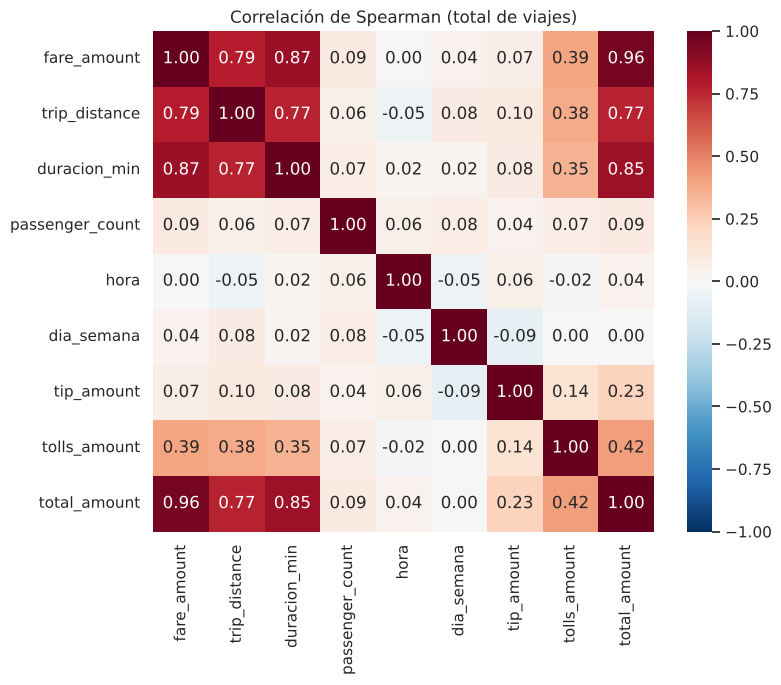

In [24]:
corr = df[["fare_amount", "trip_distance", "duracion_min", "passenger_count", "hora", "dia_semana",
                "tip_amount", "tolls_amount", "total_amount"]].corr("spearman")
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Correlación de Spearman (total de viajes)")
guardar(fig, "09_corr_spearman"); plt.show()

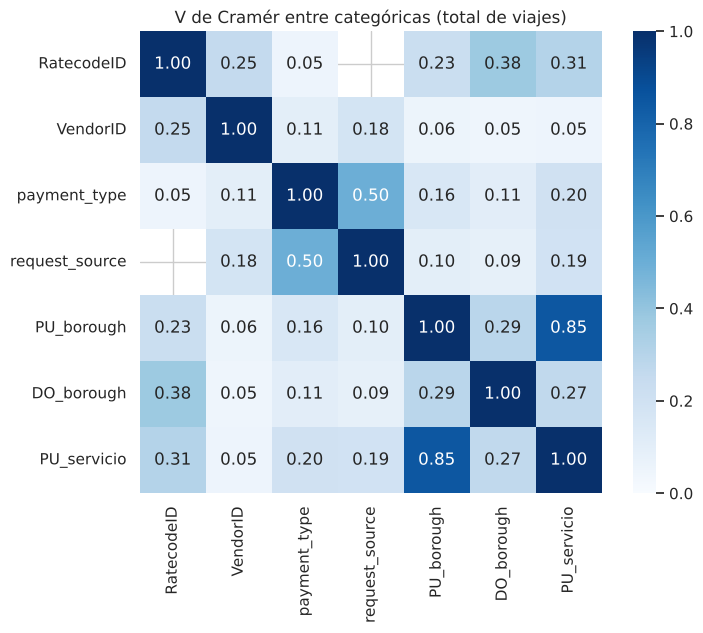

In [25]:
def cramers_v(a, b):
    t = pd.crosstab(a, b); chi2 = stats.chi2_contingency(t, correction=False)[0]
    k = min(t.shape) - 1
    return np.sqrt(chi2 / (t.values.sum() * k)) if k > 0 else np.nan

cv_cols = ["RatecodeID", "VendorID", "payment_type", "request_source", "PU_borough", "DO_borough", "PU_servicio"]
mm = df[cv_cols].copy(); mm["request_source"] = mm["request_source"].fillna("vacío")   # NaN como categoría solo para el cálculo
cv = pd.DataFrame(index=cv_cols, columns=cv_cols, dtype=float)
for a in cv_cols:
    for b in cv_cols:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(mm[a], mm[b])
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, square=True)
ax.set_title("V de Cramér entre categóricas (total de viajes)")
guardar(fig, "10_cramer_v"); plt.show()

**Qué se observa:**
- `total_amount` ≈ `fare_amount` (incluye la tarifa) y `trip_distance` ↔ `duracion_min` muy correlacionadas: todas de fin de viaje (*leakage*).
- **`payment_type` ↔ `request_source`** muy asociadas: el pedido por app solo aparece en Flex Fare (ver sección 9).
- `PU_servicio` ↔ `PU_borough` y `RatecodeID` ↔ zonas de aeropuerto: información **solapada**.

### Test χ² de independencia y regla de Cochran
La V de Cramér mide la **magnitud** de la asociación; el **test χ²** evalúa si es estadísticamente significativa
(H₀: las dos variables son independientes). Supuestos del test: observaciones independientes, categorías excluyentes y
**regla de Cochran**: al menos el 80 % de las frecuencias esperadas deben ser ≥ 5 y ninguna < 1.

In [26]:
filas = []
for i, a in enumerate(cv_cols):
    for b in cv_cols[i + 1:]:
        tabla = pd.crosstab(mm[a], mm[b])
        if min(tabla.shape) < 2:      # una de las dos queda con una sola categoría en las filas con dato: no hay test posible
            filas.append({"variable A": a, "variable B": b, "χ²": np.nan, "gl": 0, "p-valor": np.nan,
                          "V de Cramér": np.nan, "% esperadas ≥ 5": np.nan, "mín. esperada": np.nan,
                          "cumple Cochran": "No aplica (no coexisten)"})
            continue
        chi2, p, gl, esperadas = stats.chi2_contingency(tabla, correction=False)
        pct_5 = (esperadas >= 5).mean() * 100
        cochran = (pct_5 >= 80) and (esperadas.min() >= 1)
        filas.append({"variable A": a, "variable B": b, "χ²": chi2, "gl": gl, "p-valor": p,
                      "V de Cramér": cv.loc[a, b], "% esperadas ≥ 5": pct_5,
                      "mín. esperada": esperadas.min(), "cumple Cochran": "Sí" if cochran else "No"})
chi_tabla = pd.DataFrame(filas).sort_values("V de Cramér", ascending=False)
chi_tabla

,variable A,variable B,χ²,gl,p-valor,V de Cramér,% esperadas ≥ 5,mín. esperada,cumple Cochran
19,PU_borough,PU_servicio,"7,227,133.463",15,0.000,0.851,87.500,0.052,No
11,payment_type,request_source,"3,335,055.042",24,0.000,0.500,88.571,0.819,No
4,RatecodeID,DO_borough,"1,721,857.017",30,0.000,0.378,95.238,3.070,Sí
5,RatecodeID,PU_servicio,"678,160.969",15,0.000,0.306,91.667,1.756,Sí
18,PU_borough,DO_borough,"1,670,971.830",36,0.000,0.289,83.673,0.191,No
20,DO_borough,PU_servicio,"725,233.398",18,0.000,0.269,89.286,0.252,No
0,RatecodeID,VendorID,"313,629.058",10,0.000,0.255,100.000,150.361,Sí
3,RatecodeID,PU_borough,"635,681.857",30,0.000,0.229,83.333,0.405,No
14,payment_type,PU_servicio,"405,462.844",12,0.000,0.201,90.000,1.479,Sí
17,request_source,PU_servicio,"370,486.367",18,0.000,0.193,89.286,0.038,No


**Qué se observa:** con 3,3 millones de viajes **todos los tests χ² dan p ≈ 0**: se rechaza la independencia en todos los
pares evaluables. El par `RatecodeID` – `request_source` no se puede evaluar: `RatecodeID` solo existe fuera de Flex Fare y
`request_source` solo dentro, así que nunca tienen dato en la misma fila. Como pasa con el ANOVA, con un n tan grande la significancia no discrimina; lo informativo es la **magnitud (V de Cramér)**.
Los pares que **no cumplen Cochran** tienen categorías muy poco frecuentes (por ejemplo, borough EWR o Staten Island, o
`RatecodeID` 3 y 4), que generan frecuencias esperadas chicas: para esos pares el p-valor del χ² no es confiable, aunque la
V de Cramér sigue siendo una descripción válida de la asociación. Agrupar categorías raras (etapa de preparación) resolvería
el problema.

---
# 9. Valores faltantes: cuántos, dónde y qué mecanismo
Mecanismos: **MCAR** (al azar), **MAR** (depende de otras variables observadas), **MNAR** (depende del propio valor),
**estructural / por diseño** (el dato no existe).

In [27]:
falt = pd.DataFrame({"NaN": df[COLS_ORIGINALES].isna().sum(), "% NaN": df[COLS_ORIGINALES].isna().mean() * 100})
falt = falt[falt["NaN"] > 0].sort_values("% NaN", ascending=False)
falt

,NaN,% NaN
request_source,2415867,72.403
passenger_count,921181,27.607
RatecodeID,921181,27.607
store_and_fwd_flag,921181,27.607
congestion_surcharge,921181,27.607
Airport_fee,921181,27.607


¿Las 5 columnas faltan juntas en las mismas filas? True


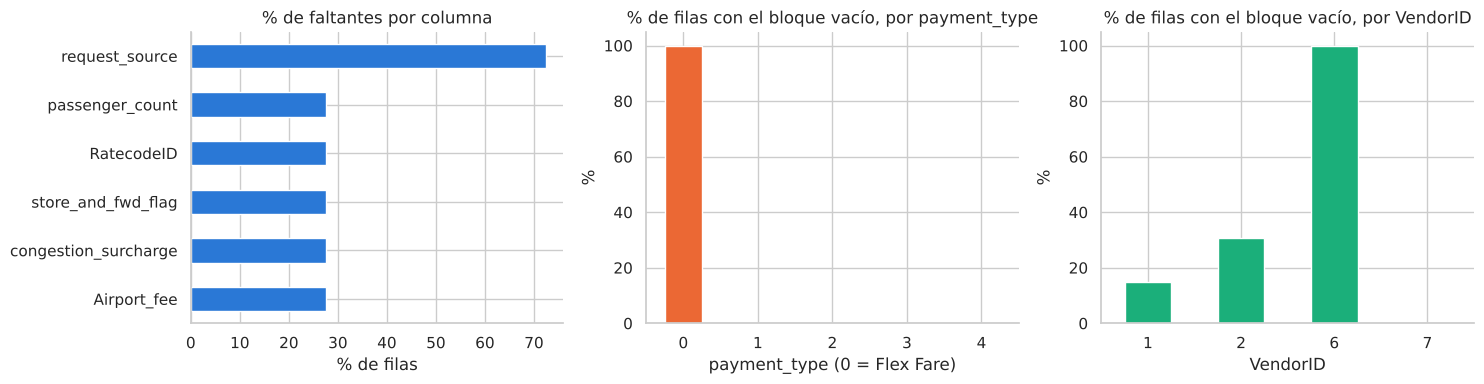


request_source según payment_type:


request_source,A,CC,EH0004,EH0010,HV0003,HV0005,vacío
payment_type,,,,,,,
0,103753,573,6253,263,628774,181233,332
1,0,0,0,0,0,0,2052104
2,0,0,0,0,0,0,329477
3,0,0,0,0,0,0,10397
4,0,0,0,0,0,0,23557


In [28]:
bloque = ["passenger_count", "RatecodeID", "store_and_fwd_flag", "congestion_surcharge", "Airport_fee"]
faltan_juntas = df[bloque].isna().all(axis=1)
print("¿Las 5 columnas faltan juntas en las mismas filas?", (faltan_juntas == df["passenger_count"].isna()).all())

por_pago = df.assign(f=df["passenger_count"].isna()).groupby("payment_type")["f"].mean().mul(100)
por_vendor = df.assign(f=df["passenger_count"].isna()).groupby("VendorID")["f"].mean().mul(100)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
falt["% NaN"].plot.barh(ax=axes[0], color=AZUL); axes[0].invert_yaxis()
axes[0].set(title="% de faltantes por columna", xlabel="% de filas")
por_pago.plot.bar(ax=axes[1], color=NARANJA)
axes[1].set(title="% de filas con el bloque vacío, por payment_type", xlabel="payment_type (0 = Flex Fare)", ylabel="%")
por_vendor.plot.bar(ax=axes[2], color=VERDE)
axes[2].set(title="% de filas con el bloque vacío, por VendorID", xlabel="VendorID", ylabel="%")
for ax in axes[1:]: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); guardar(fig, "11_faltantes_patron"); plt.show()

print("\nrequest_source según payment_type:")
pd.crosstab(df["payment_type"], df["request_source"].fillna("vacío"))

In [29]:
# Faltantes "disfrazados": valores que en realidad significan "no sé"
nf = df["payment_type"] != 0     # fuera del bloque Flex Fare
disfr = pd.DataFrame({
    "casos": [(df["passenger_count"] == 0).sum(), (df["RatecodeID"] == 99).sum()],
    "% del total": [(df["passenger_count"] == 0).mean() * 100, (df["RatecodeID"] == 99).mean() * 100],
}, index=["passenger_count = 0", "RatecodeID = 99 (desconocido)"])
display(disfr)
print("% de RatecodeID = 99 según VendorID (viajes no Flex Fare):")
display(df[nf].groupby("VendorID")["RatecodeID"].apply(lambda s: (s == 99).mean() * 100).to_frame("% RC=99"))
print("% de passenger_count = 0 según VendorID (viajes no Flex Fare):")
df[nf].groupby("VendorID")["passenger_count"].apply(lambda s: (s == 0).mean() * 100).to_frame("% pc=0")

,casos,% del total
passenger_count = 0,7478,0.224
RatecodeID = 99 (desconocido),76958,2.306


% de RatecodeID = 99 según VendorID (viajes no Flex Fare):


,% RC=99
VendorID,
1,15.641
2,0.001
7,0.000


% de passenger_count = 0 según VendorID (viajes no Flex Fare):


,% pc=0
VendorID,
1,1.323
2,0.052
7,0.000


**Qué se observa:**

| Faltante | % | Mecanismo | Evidencia |
|---|---|---|---|
| Bloque de 5 columnas (`passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, `Airport_fee`) | 27,6 % | **Estructural / por diseño** | Faltan juntas y **solo** en `payment_type = 0` (Flex Fare): para la tarifa pactada por app el sistema no registra esos campos. No es MCAR: el % pasa de 0 a 100 según el tipo de pago |
| `request_source` | 72,4 % | **Estructural** | Solo tiene valor en los viajes Flex Fare (pedidos por app: Uber, Lyft y otros); en los viajes de calle el dato no existe |
| `passenger_count = 0` | 0,2 % | **MAR** | Se concentra en un proveedor (`VendorID = 1`) |
| `RatecodeID = 99` | 2,3 % | **MAR** | Proviene casi exclusivamente de `VendorID = 1` |

---
# 10. Datos atípicos y errores
Primero se separan los **valores imposibles** (errores de registro) de los **atípicos estadísticos** (que pueden ser legítimos).
Para los atípicos se comparan dos criterios: **IQR (robusto)** y **media ± 3σ (asume normalidad)**.
En esta etapa solo se **identifican**: el tratamiento se decide después del split.

In [30]:
imposibles = {
    "Pickup fuera de agosto 2026": ~df["tpep_pickup_datetime"].between("2026-08-01", "2026-08-31 23:59:59"),
    "Duración <= 0 min": df["duracion_min"] <= 0,
    "Duración > 24 h": df["duracion_min"] > 24 * 60,
    "Distancia = 0": df["trip_distance"] == 0,
    "fare_amount < 0": df["fare_amount"] < 0,
    "fare_amount en [0, 3) USD (incluye tarifa 0; debajo de la bajada de bandera)": df["fare_amount"].between(0, 3, inclusive="left"),
    "Zona desconocida (264/265)": df["PULocationID"].isin([264, 265]) | df["DOLocationID"].isin([264, 265]),
    "Filas duplicadas exactas": df.duplicated(),
}
err = pd.DataFrame({"casos": {k: v.sum() for k, v in imposibles.items()}})
err["% del total"] = err["casos"] / len(df) * 100
err

,casos,% del total
Pickup fuera de agosto 2026,15,0.000
Duración <= 0 min,43185,1.294
Duración > 24 h,42,0.001
Distancia = 0,119059,3.568
fare_amount < 0,14049,0.421
"fare_amount en [0, 3) USD (incluye tarifa 0; debajo de la bajada de bandera)",3793,0.114
Zona desconocida (264/265),26773,0.802
Filas duplicadas exactas,7,0.000


In [31]:
def atipicos(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    mu, sd = s.mean(), s.std()
    return pd.Series({"lím. inf IQR": q1 - 1.5 * iqr, "lím. sup IQR": q3 + 1.5 * iqr,
                      "% fuera IQR": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100,
                      "lím. sup 3σ": mu + 3 * sd, "% fuera 3σ": ((s - mu).abs() > 3 * sd).mean() * 100})

pd.DataFrame({c: atipicos(df[c]) for c in ["fare_amount", "trip_distance", "duracion_min"]}).T

,lím. inf IQR,lím. sup IQR,% fuera IQR,lím. sup 3σ,% fuera 3σ
fare_amount,-14.150,50.250,6.705,80.460,1.204
trip_distance,-3.640,8.920,9.859,"1,266.557",0.001
duracion_min,-11.967,42.567,4.326,682.343,0.016


Atípicos superiores según IQR (fare > 50.2 USD): 217,160 viajes (6.5%)


,% dentro de los atípicos,% en todo el dataset
PU_servicio,,
Airports,55.129,7.222
Boro Zone,14.453,9.368
EWR,0.183,0.014
Yellow Zone,30.235,83.396


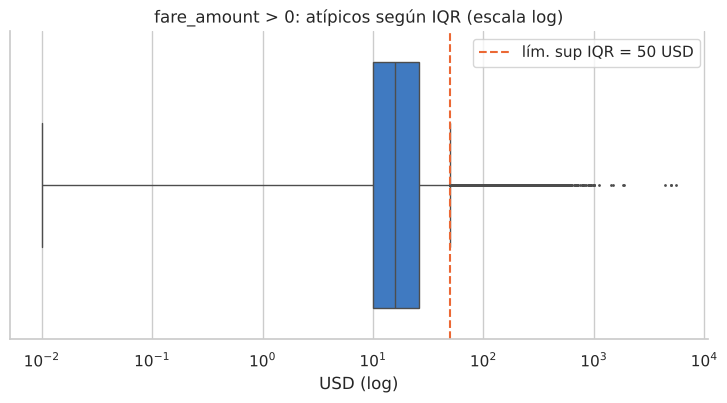

Tarifas más altas:


,fare_amount,trip_distance,duracion_min,RatecodeID,payment_type,PU_zona,DO_zona
51465,"5,525.990",0.000,0.000,5.000,2,Kips Bay,Murray Hill
2272258,"5,050.000",0.000,0.000,5.000,3,West Village,West Village
1101554,"5,000.000",0.000,0.000,99.000,1,NV,NV
773864,"4,385.000",0.000,0.000,99.000,1,NV,NV
440380,"1,860.800",272.200,320.833,4.000,2,JFK Airport,NaN
2122792,"1,849.600",274.350,269.300,4.000,4,JFK Airport,NaN
514305,"1,501.000",228.730,222.767,4.000,2,JFK Airport,East Concourse/Concourse Village
898881,"1,421.410",0.000,0.000,5.000,3,Penn Station/Madison Sq West,Penn Station/Madison Sq West


In [32]:
# ¿Quiénes son los atípicos superiores del target?
ls = atipicos(df["fare_amount"])["lím. sup IQR"]
alto = df["fare_amount"] > ls
perfil = pd.DataFrame({"% dentro de los atípicos": df.loc[alto, "PU_servicio"].value_counts(normalize=True) * 100,
                       "% en todo el dataset": df["PU_servicio"].value_counts(normalize=True) * 100})
print(f"Atípicos superiores según IQR (fare > {ls:.1f} USD): {alto.sum():,} viajes ({alto.mean():.1%})")
display(perfil)

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(x=df.loc[df["fare_amount"] > 0, "fare_amount"], ax=ax, color=AZUL, fliersize=1)
ax.axvline(ls, color=NARANJA, ls="--", label=f"lím. sup IQR = {ls:.0f} USD")
ax.set(xscale="log", title="fare_amount > 0: atípicos según IQR (escala log)", xlabel="USD (log)"); ax.legend()
guardar(fig, "12_atipicos_target"); plt.show()

print("Tarifas más altas:")
df.nlargest(8, "fare_amount")[["fare_amount", "trip_distance", "duracion_min", "RatecodeID", "payment_type", "PU_zona", "DO_zona"]]

**Qué se observa:**
- **Errores (valores imposibles):** duraciones ≤ 0, distancias 0, tarifas negativas o menores a la bajada de bandera,
  zonas desconocidas, fechas fuera del mes. Son pocos en proporción, pero existen.
- **Atípicos estadísticos del target:** el criterio IQR marca el 6,7 % de los viajes, y el **55 % de ellos sale de aeropuertos**
  (que son solo el 7 % del total) → son **legítimos**: responden a otro régimen tarifario.
- El criterio **3σ** marca apenas 1,2 % porque el desvío está inflado por los valores absurdos (para la distancia, el límite
  3σ ¡es 1.266 millas!): con distribuciones tan asimétricas el **IQR es el criterio adecuado**.
- Las tarifas más altas (USD 4.000–5.500) tienen **distancia y duración 0** y tarifa negociada o desconocida → **errores de carga**.

---
# 11. ¿Qué se observa en el EDA? (síntesis)
| Aspecto | Observación |
|---|---|
| Dimensiones | 3.336.716 viajes × 21 variables (agosto 2026) |
| Tipos de variables | Numéricas continuas (montos, distancia, tiempos), numéricas discretas (pasajeros, recargos), categóricas nominales codificadas con números (zonas, tarifa, proveedor, medio de pago) |
| Target `fare_amount` | Mediana 15,6 USD, IQR 16,1; muy asimétrico (cola derecha) y leptocúrtico; escalonado en saltos de USD 0,70; pico en USD 70 (JFK) |
| Asociación con el target | Fuerte con zonas de origen/destino y tipo de tarifa (η²); muy fuerte con distancia y duración, pero son *leakage* |
| Faltantes | Bloque estructural de 5 columnas = viajes Flex Fare (27,6 %); `request_source` estructural (solo Flex Fare); faltantes disfrazados MAR (`passenger_count = 0`, `RatecodeID = 99`) |
| Errores | Duraciones ≤ 0, distancias 0, tarifas negativas o < USD 3, zonas desconocidas, fechas fuera del mes |
| Atípicos | IQR: 6,7 % del target, mayormente aeropuertos → legítimos. Extremos con distancia 0 → errores |
| Redundancias | Distancia ↔ duración; `PU_servicio` ↔ borough; `RatecodeID` ↔ aeropuerto; `payment_type` ↔ `request_source` |

### Rol de cada variable tras el EDA
El *leakage* se define por el problema (qué se conoce al subir el pasajero); el EDA **confirma** la hipótesis con evidencia
(detalle de las 20 variables en la sección 7.3).

| Variable | Rol tras el EDA | Evidencia del EDA |
|---|---|---|
| `fare_amount` | **Target** | Muy asimétrico, con errores (negativos, < USD 3) y pico de tarifa fija → requiere tratamiento |
| `PULocationID`, `DOLocationID` | **Feature** | η² ≈ 0,26–0,28 (efecto fuerte); alta cardinalidad (261) → codificación especial |
| `RatecodeID` | **Feature** | η² = 0,36 (el más alto); incluye el código 99 = faltante disfrazado (MAR) |
| `tpep_pickup_datetime` (hora, día) | **Feature a evaluar** | η² < 0,01 (efecto despreciable), aunque la demanda cambia mucho por hora → se decide en la selección de features |
| `passenger_count` | **Feature a evaluar** | Spearman ≈ 0,09 (despreciable); IQR = 0 (casi todo 1); ceros = faltante disfrazado |
| `VendorID` | **Feature a evaluar** | η² ≈ 0,01 (despreciable); explica los faltantes disfrazados (MAR) |
| `trip_distance`, `tpep_dropoff_datetime` | **Excluidas (leakage)** | Spearman 0,79–0,87 con el target: predecirían "demasiado bien" con información que no existe al subir |
| `total_amount`, `tip_amount`, `tolls_amount` | **Excluidas (leakage)** | `total_amount` contiene al target (ρ ≈ 0,96); peajes ρ ≈ 0,39; propina y peajes se conocen al pagar |
| `extra`, `congestion_surcharge`, `cbd_congestion_fee` | **Excluidas** | Asociación débil o despreciable (\|ρ\| ≤ 0,21); dependen del recorrido o de la hora |
| `Airport_fee` | **Excluida (redundante)** | Asociación moderada (ρ ≈ 0,46), pero el ~97 % coincide con subir en JFK/LaGuardia → ya está en `PULocationID` |
| `mta_tax`, `improvement_surcharge` | **Excluidas** | Casi constantes (98–99 % un mismo valor) → no aportan variación |
| `store_and_fwd_flag` | **Excluida** | Dato técnico; η² ≈ 0,02; 27,6 % faltante estructural |
| `request_source` | **Excluida** | Solo existe en viajes Flex Fare (faltante estructural); η² ≈ 0,02 |
| `payment_type` | **Excluida como feature** | Se conoce al pagar; se usa para definir la población (Flex Fare) |

**Decisiones anotadas para la preparación (se resuelven en las secciones 12 a 16):**
- Viajes con tarifa fija (`RatecodeID = 2`): ¿se excluyen del alcance o se mantienen?
- Población: ¿se excluyen los viajes Flex Fare, cuyo precio no lo calcula el taxímetro?
- Tratamiento de errores, faltantes disfrazados y atípicos identificados en las secciones 9 y 10.

**Trabajo futuro:** reorientar el problema al taxista como cliente, con target = ingreso por minuto ((tarifa + propina) / duración)
por zona y horario, para identificar dónde y cuándo rinde más trabajar.

**Próximo paso:** limpieza básica y definición de la población (sección 12).

---
# 12. Limpieza básica y definición de la población (previas al split)

### 12.1 Criterio: ¿qué puede ir antes del split?
Un paso puede ir antes del split **solo si es una regla fija que no se calcula a partir de los datos** (no usa medias,
medianas, percentiles ni ningún estadístico). Así no se filtra información del test al entrenamiento (*data leakage*).
Por ejemplo, "una tarifa menor a la bajada de bandera es imposible" vale igual para cualquier viaje, esté en train o en test.
Todo lo que **aprende parámetros de los datos** (límites de outliers por IQR, imputación por moda o mediana, escalado) va
**después del split**, calculado solo en train.

### Pasos de limpieza y su justificación
| # | Paso | Evidencia en el EDA | Justificación | ¿Usa estadísticos de los datos? |
|---|---|---|---|---|
| 1 | Eliminar **filas duplicadas** exactas | Sección 10: 7 filas | Un mismo viaje registrado dos veces es un error de carga; duplicarlo le daría doble peso en el modelo | No |
| 2 | Eliminar viajes con **pickup fuera de agosto 2026** | Sección 10: 15 viajes (uno de 2009 por error de reloj; el resto del 31/07 a la noche) | El dataset es de agosto 2026; un viaje de 2009 es imposible y los del 31/07 no pertenecen al período analizado | No |
| 3 | Eliminar **tarifa menor a USD 3** (incluye negativas y cero) | Secciones 3 y 10: tarifas negativas (reversiones), cero y entre 0 y 3 | La bajada de bandera del taxímetro es USD 3: ninguna tarifa real puede ser menor. Las negativas son reversiones o reembolsos, no viajes | No |
| 4 | Eliminar **duración ≤ 0 o > 24 h** | Sección 10: duraciones negativas o nulas y de varios días | Un viaje no puede terminar antes de empezar ni durar más de un día: son errores del reloj o taxímetros que quedaron encendidos | No |
| 5 | Eliminar **distancia = 0** | Sección 10: ~119 mil viajes en el dataset crudo | Un viaje cobrado sin distancia recorrida indica falla del taxímetro o viaje anulado; además la distancia se usará para construir una feature | No |
| 6 | Eliminar **zona de origen o destino desconocida** (IDs 264 y 265) | Sección 10: ~27 mil viajes en el dataset crudo | Origen y destino son las features principales del problema (η² fuerte): sin ellas no hay nada que predecir | No |

### Definición de la población (alcance del problema)
Además de los errores, se excluyen viajes que **no son errores** pero cuyo precio **no lo calcula el taxímetro**. El problema
es cotizar la tarifa de taxímetro antes del viaje: incluir precios que siguen otra lógica mezclaría dos mecanismos
distintos en el mismo target. También son reglas fijas (se define por el tipo de viaje), así que pueden ir antes del split.

| # | Paso | Evidencia | Justificación | ¿Usa estadísticos de los datos? |
|---|---|---|---|---|
| 7 | Excluir viajes **Flex Fare** (`payment_type = 0`) | 27,6 % de los viajes del dataset crudo. Solo el ~4 % de sus tarifas sigue el patrón del taxímetro (USD 3 + 0,70·n), contra ~100 % de la tarifa estándar. Casi todos fueron pedidos por app (Uber y Lyft en `request_source`). Traen 5 columnas vacías por diseño | El precio se **pacta de antemano en la app**, no lo calcula el taxímetro: es otra población con otra lógica de precio | No |
| 8 | Excluir **tarifa fija JFK** (`RatecodeID = 2`) | ~2,5 % de los viajes. Prácticamente el 100 % paga exactamente USD 70; la correlación con la distancia es nula (Spearman ≈ 0) | El precio es **fijo por regulación** (JFK ↔ Manhattan): no hay nada que predecir; un modelo solo aprendería "si es JFK, vale 70" | No |
| 9 | Excluir **tarifa negociada** (`RatecodeID = 5`) | ~0,5 % de los viajes. Spearman con la distancia ≈ 0,33 (contra ≈ 0,92 en la tarifa estándar); solo ~13 % sigue el patrón del taxímetro; concentra los valores absurdos del EDA (miles de USD con distancia mínima) | El precio lo **pactan conductor y pasajero**: no responde a la lógica del taxímetro y no es predecible con datos a priori | No |

### Faltantes disfrazados
| # | Paso | Evidencia | Justificación | ¿Usa estadísticos de los datos? |
|---|---|---|---|---|
| 10 | Convertir `passenger_count = 0` y `RatecodeID = 99` a **NaN** | Sección 9 del EDA: 0 pasajeros es imposible en un viaje cobrado; 99 = "desconocido" según el diccionario. Ambos se concentran en `VendorID = 1` (MAR) | Son faltantes "disfrazados" de valor: representarlos como NaN hace explícito que falta el dato. **No se imputan acá**: la imputación usa estadísticos (moda) y va después del split, calculada en train | No (solo cambia la representación) |

**Quedan para las etapas siguientes:**
- **Selección de columnas** (leakage, casi constantes, técnicas): se hace en la etapa de **selección de features**, con la evidencia del EDA (sección 7.3).
- **Outliers estadísticos**: se tratan después del split con estadística robusta (IQR).

In [33]:
# Se libera la memoria del EDA y se parte nuevamente del dataset original, sin columnas auxiliares
import gc
for nombre in ["df", "muestra", "mm", "cv", "corr", "resumen_20"]:
    globals().pop(nombre, None)
gc.collect()

FIG_DIR = Path("figures/limpieza"); FIG_DIR.mkdir(parents=True, exist_ok=True)

In [34]:
df = pd.read_parquet(DATA_PARQUET)
n_original = len(df)
print(f"Dataset original: {n_original:,} viajes × {df.shape[1]} variables")

Dataset original: 3,336,716 viajes × 21 variables


---
## Evidencia para la definición de la población
Antes de aplicar las reglas, se verifica con los datos que Flex Fare, la tarifa fija JFK y la negociada siguen una lógica de
precio distinta a la del taxímetro. Indicadores: % de tarifas con el patrón del taxímetro (USD 3 + 0,70·n), % de tarifas
exactamente iguales a USD 70 y correlación de Spearman entre tarifa y distancia (en el taxímetro, la tarifa depende de la distancia).

In [35]:
from scipy import stats
patron = (df["fare_amount"].mod(0.7).round(2) == 0.2)
grupos = {
    "Tarifa estándar (RatecodeID = 1)": (df["payment_type"] != 0) & (df["RatecodeID"] == 1),
    "Flex Fare (payment_type = 0)":     df["payment_type"] == 0,
    "Tarifa fija JFK (RatecodeID = 2)": (df["payment_type"] != 0) & (df["RatecodeID"] == 2),
    "Tarifa negociada (RatecodeID = 5)": (df["payment_type"] != 0) & (df["RatecodeID"] == 5),
}
validos = (df["fare_amount"] >= 3) & (df["trip_distance"] > 0)     # solo para que la comparación no la distorsionen los errores
filas = []
for nombre, m in grupos.items():
    x = df[m & validos]
    filas.append({"grupo": nombre, "viajes": len(x), "% del total": len(x) / len(df) * 100,
                  "% con patrón de taxímetro": patron[m & validos].mean() * 100,
                  "% exactamente USD 70": (x["fare_amount"] == 70).mean() * 100,
                  "mediana tarifa (USD)": x["fare_amount"].median(),
                  "Spearman tarifa–distancia": stats.spearmanr(x["fare_amount"], x["trip_distance"])[0]})
pd.DataFrame(filas).set_index("grupo")

,viajes,% del total,% con patrón de taxímetro,% exactamente USD 70,mediana tarifa (USD),Spearman tarifa–distancia
grupo,,,,,,
Tarifa estándar (RatecodeID = 1),2176680,65.234,99.960,0.000,12.800,0.922
Flex Fare (payment_type = 0),838120,25.118,4.095,0.030,22.650,0.708
Tarifa fija JFK (RatecodeID = 2),79220,2.374,0.001,99.955,70.000,-0.025
Tarifa negociada (RatecodeID = 5),18964,0.568,13.067,3.116,82.000,0.327


**Lectura:** la tarifa estándar sigue el patrón del taxímetro casi en el 100 % de los casos y está fuertemente asociada a la
distancia (ρ ≈ 0,92). Los otros tres grupos no siguen esa lógica:
- **Flex Fare** casi nunca sigue el patrón del taxímetro (~4 %): su precio se fija en la app antes del viaje. Se relaciona con la distancia (ρ ≈ 0,71) porque la app también la usa para cotizar, pero con otra fórmula.
- **Tarifa fija JFK** es siempre USD 70 y no depende de la distancia (ρ ≈ 0).
- **Tarifa negociada** depende débilmente de la distancia (ρ ≈ 0,33) y casi no sigue el patrón del taxímetro.

Se confirma que son **otras lógicas de precio**: se excluyen por **alcance del problema**, no por ser errores.
El modelo resultante cotiza viajes **de calle con tarifa de taxímetro** (estándar, Newark y Nassau/Westchester).

---
## Aplicación de las reglas
Cada regla se aplica en orden y se registra cuántas filas elimina, para que la limpieza quede trazable.

In [36]:
registro = []

def aplicar(df, nombre, condicion_a_eliminar):
    # Elimina las filas donde la condición es verdadera y registra cuántas fueron
    n_elim = int(condicion_a_eliminar.sum())
    registro.append({"paso": nombre, "filas eliminadas": n_elim})
    return df.loc[~condicion_a_eliminar]

# 1. Duplicados exactos
df = aplicar(df, "1. Filas duplicadas", df.duplicated())

# 2. Pickup fuera de agosto 2026
fuera = ~df["tpep_pickup_datetime"].between("2026-08-01", "2026-08-31 23:59:59")
df = aplicar(df, "2. Pickup fuera de agosto 2026", fuera)

# 3. Tarifa menor a la bajada de bandera (USD 3), incluye negativas y cero
df = aplicar(df, "3. Tarifa < USD 3 (incluye negativas y cero)", df["fare_amount"] < 3)

# 4. Duración imposible (la duración se calcula solo para aplicar la regla; no se guarda como columna)
duracion_min = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
df = aplicar(df, "4. Duración ≤ 0 o > 24 h", (duracion_min <= 0) | (duracion_min > 24 * 60))

# 5. Distancia cero
df = aplicar(df, "5. Distancia = 0", df["trip_distance"] == 0)

# 6. Zona de origen o destino desconocida (IDs 264 y 265 de la tabla TLC)
desconocida = df["PULocationID"].isin([264, 265]) | df["DOLocationID"].isin([264, 265])
df = aplicar(df, "6. Zona de origen o destino desconocida", desconocida)

# ---- Definición de la población ----
# 7. Flex Fare: precio pactado por app, no calculado por el taxímetro
df = aplicar(df, "7. Población: excluir Flex Fare (payment_type = 0)", df["payment_type"] == 0)

# 8. Tarifa fija JFK: precio fijo por regulación (USD 70)
df = aplicar(df, "8. Población: excluir tarifa fija JFK (RatecodeID = 2)", df["RatecodeID"] == 2)

# 9. Tarifa negociada: precio pactado entre conductor y pasajero
df = aplicar(df, "9. Población: excluir tarifa negociada (RatecodeID = 5)", df["RatecodeID"] == 5)

limpieza = pd.DataFrame(registro)
limpieza["% del original"] = limpieza["filas eliminadas"] / n_original * 100
limpieza["filas restantes"] = n_original - limpieza["filas eliminadas"].cumsum()
total = pd.DataFrame([{"paso": "TOTAL", "filas eliminadas": limpieza["filas eliminadas"].sum(),
                       "% del original": limpieza["filas eliminadas"].sum() / n_original * 100,
                       "filas restantes": len(df)}])
pd.concat([limpieza, total], ignore_index=True)

,paso,filas eliminadas,% del original,filas restantes
0,1. Filas duplicadas,7,0.000,3336709
1,2. Pickup fuera de agosto 2026,15,0.000,3336694
2,3. Tarifa < USD 3 (incluye negativas y cero),17835,0.535,3318859
3,4. Duración ≤ 0 o > 24 h,42217,1.265,3276642
4,5. Distancia = 0,113867,3.413,3162775
5,6. Zona de origen o destino desconocida,21974,0.659,3140801
6,7. Población: excluir Flex Fare (payment_type ...,834451,25.008,2306350
7,8. Población: excluir tarifa fija JFK (Ratecod...,78309,2.347,2228041
8,9. Población: excluir tarifa negociada (Rateco...,15888,0.476,2212153
9,TOTAL,1124563,33.703,2212153


### Paso 10: faltantes disfrazados → NaN
No elimina filas: cambia la representación del dato faltante. La imputación se hace después del split.

In [37]:
n_pc0 = int((df["passenger_count"] == 0).sum())
n_rc99 = int((df["RatecodeID"] == 99).sum())
df = df.copy()
df.loc[df["passenger_count"] == 0, "passenger_count"] = np.nan
df.loc[df["RatecodeID"] == 99, "RatecodeID"] = np.nan
print(f"passenger_count = 0 → NaN: {n_pc0:,} viajes ({n_pc0 / len(df):.2%})")
print(f"RatecodeID = 99 → NaN:    {n_rc99:,} viajes ({n_rc99 / len(df):.2%})")
df[["passenger_count", "RatecodeID"]].isna().sum().to_frame("NaN después del paso 10")

passenger_count = 0 → NaN: 7,002 viajes (0.32%)
RatecodeID = 99 → NaN:    72,329 viajes (3.27%)


,NaN después del paso 10
passenger_count,7002
RatecodeID,72329


In [38]:
# Observación sobre RatecodeID = 99: ¿su tarifa se comporta como la estándar?
rc_nan = df["RatecodeID"].isna()
comp = pd.DataFrame({
    "RatecodeID desconocido (NaN)": [rc_nan.sum(), (df.loc[rc_nan, "fare_amount"].mod(0.7).round(2) == 0.2).mean() * 100,
                                     df.loc[rc_nan, "VendorID"].eq(1).mean() * 100],
    "RatecodeID = 1 (estándar)": [(df["RatecodeID"] == 1).sum(),
                                  (df.loc[df["RatecodeID"] == 1, "fare_amount"].mod(0.7).round(2) == 0.2).mean() * 100,
                                  df.loc[df["RatecodeID"] == 1, "VendorID"].eq(1).mean() * 100],
}, index=["viajes", "% con patrón de taxímetro", "% del proveedor VendorID = 1"])
comp

,RatecodeID desconocido (NaN),RatecodeID = 1 (estándar)
viajes,"72,329.000","2,130,969.000"
% con patrón de taxímetro,1.401,99.959
% del proveedor VendorID = 1,99.985,18.319


**Observación para la imputación:** los viajes con `RatecodeID` desconocido **casi nunca siguen el patrón del taxímetro
estándar** y vienen todos del mismo proveedor (`VendorID = 1`). Imputarlos con la moda (1 = estándar) sería asumir algo que
los datos contradicen. Queda como decisión para después del split: tratarlos como una categoría propia ("desconocido")
en lugar de imputar la moda.

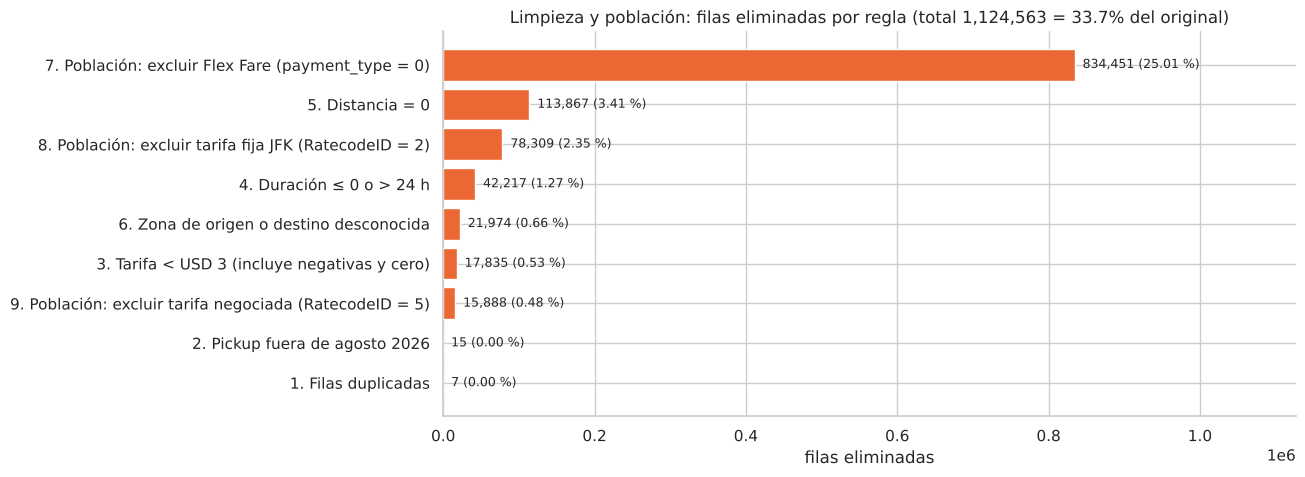

In [39]:
fig, ax = plt.subplots(figsize=(11, 5))
d = limpieza.sort_values("filas eliminadas")
ax.barh(d["paso"], d["filas eliminadas"], color=NARANJA)
for y, (v, p) in enumerate(zip(d["filas eliminadas"], d["% del original"])):
    ax.text(v, y, f"  {v:,} ({p:.2f} %)", va="center", fontsize=9)
ax.set(title=f"Limpieza y población: filas eliminadas por regla (total {limpieza['filas eliminadas'].sum():,} "
             f"= {limpieza['filas eliminadas'].sum() / n_original:.1%} del original)",
       xlabel="filas eliminadas", ylabel="")
ax.set_xlim(0, d["filas eliminadas"].max() * 1.35)
guardar(fig, "01_limpieza_filas_eliminadas"); plt.show()

**Lectura:** los **errores** (pasos 1 a 6) eliminan el 5,9 % de los viajes; la mayor parte es distancia cero, seguida de
duraciones imposibles. La **definición de la población** (pasos 7 a 9) excluye otra parte importante, casi toda por Flex Fare:
no son errores sino viajes con otra lógica de precio. El orden de los pasos
cambia cuántas filas se le atribuyen a cada regla (una fila con varios errores se cuenta solo en la primera regla que la
elimina), pero no cambia el total.

---
## Verificación
Se comprueba que no quede ningún caso de los errores eliminados y cómo queda el target.

In [40]:
dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
verificacion = pd.Series({
    "duplicados": df.duplicated().sum(),
    "pickup fuera de agosto": (~df["tpep_pickup_datetime"].between("2026-08-01", "2026-08-31 23:59:59")).sum(),
    "tarifa < USD 3": (df["fare_amount"] < 3).sum(),
    "duración ≤ 0 o > 24 h": ((dur <= 0) | (dur > 24 * 60)).sum(),
    "distancia = 0": (df["trip_distance"] == 0).sum(),
    "zona desconocida": (df["PULocationID"].isin([264, 265]) | df["DOLocationID"].isin([264, 265])).sum(),
    "Flex Fare": (df["payment_type"] == 0).sum(),
    "tarifa fija JFK": (df["RatecodeID"] == 2).sum(),
    "tarifa negociada": (df["RatecodeID"] == 5).sum(),
    "passenger_count = 0": (df["passenger_count"] == 0).sum(),
    "RatecodeID = 99": (df["RatecodeID"] == 99).sum(),
}, name="casos restantes")
verificacion.to_frame()

,casos restantes
duplicados,0
pickup fuera de agosto,0
tarifa < USD 3,0
duración ≤ 0 o > 24 h,0
distancia = 0,0
zona desconocida,0
Flex Fare,0
tarifa fija JFK,0
tarifa negociada,0
passenger_count = 0,0


In [41]:
antes = pd.read_parquet(DATA_PARQUET, columns=["fare_amount"])["fare_amount"]
comparacion = pd.DataFrame({"antes de la limpieza": antes.describe(percentiles=[.25, .5, .75, .99]),
                            "después de la limpieza": df["fare_amount"].describe(percentiles=[.25, .5, .75, .99])})
comparacion

,antes de la limpieza,después de la limpieza
count,"3,336,716.000","2,212,153.000"
mean,21.169,17.072
std,19.764,13.227
min,"-1,849.600",3.000
25%,10.000,8.700
50%,15.600,12.800
75%,26.100,19.800
99%,84.000,69.500
max,"5,525.990","1,501.000"


**Lectura:** desaparecen los valores imposibles (mínimo negativo → mínimo USD 3). La mediana baja porque se excluyeron
poblaciones con tarifas más altas (Flex Fare, JFK a USD 70, negociadas): el target queda limitado a la tarifa de taxímetro.
Los **valores extremos altos** que quedan **siguen presentes a propósito**: no son imposibles por regla, son atípicos
estadísticos y se analizan después del split con estadística robusta (IQR).

---
# 13. Wrangling (previo al split)
*Wrangling* es reacomodar o enriquecer los datos **sin corregirlos ni calcular estadísticos**: unir tablas, extraer
información de una columna o ajustar tipos. Cada valor nuevo se calcula **fila por fila, mirando solo ese viaje**
(la hora de un viaje no depende de los demás viajes), por eso puede hacerse antes del split sin *data leakage*.

| Paso | Qué se agrega | Para qué |
|---|---|---|
| Unir con la tabla de zonas TLC | `PU_borough`, `DO_borough`, `PU_zona`, `DO_zona`, `PU_servicio`, `DO_servicio` | Interpretar las zonas y tener una versión agrupada (borough) de la variable de alta cardinalidad |
| Extraer de la fecha de pickup | `hora` (0–23) y `dia_semana` (0 = lunes) | Son las variables que se conocen al subir; la fecha completa no se usa como feature |
| Ajustar tipos | Zonas, `RatecodeID`, `VendorID` y boroughs a tipo categórico | Son categóricas codificadas con números (sección 1): el tipo lo deja explícito |

In [42]:
zonas = pd.read_csv(DATA_ZONES).set_index("LocationID")
for pref, col in [("PU", "PULocationID"), ("DO", "DOLocationID")]:
    df[f"{pref}_borough"]  = df[col].map(zonas["Borough"])
    df[f"{pref}_zona"]     = df[col].map(zonas["Zone"])
    df[f"{pref}_servicio"] = df[col].map(zonas["service_zone"])

df["hora"] = df["tpep_pickup_datetime"].dt.hour
df["dia_semana"] = df["tpep_pickup_datetime"].dt.dayofweek      # 0 = lunes ... 6 = domingo

categoricas = ["VendorID", "RatecodeID", "PULocationID", "DOLocationID",
               "PU_borough", "DO_borough", "PU_servicio", "DO_servicio"]
for c in categoricas:
    df[c] = df[c].astype("category")

print(f"Dataset luego del wrangling: {len(df):,} viajes × {df.shape[1]} columnas")
df[["PULocationID", "PU_borough", "PU_zona", "DOLocationID", "DO_borough", "hora", "dia_semana"]].head()

Dataset luego del wrangling: 2,212,153 viajes × 29 columnas


,PULocationID,PU_borough,PU_zona,DOLocationID,DO_borough,hora,dia_semana
0,140,Manhattan,Lenox Hill East,262,Manhattan,0,5
1,140,Manhattan,Lenox Hill East,262,Manhattan,0,5
2,140,Manhattan,Lenox Hill East,263,Manhattan,0,5
3,164,Manhattan,Midtown South,80,Brooklyn,0,5
4,148,Manhattan,Lower East Side,141,Manhattan,0,5


---
# 14. Split del dataset (train / test)
**Criterio elegido:** partición **aleatoria 80 % train / 20 % test**, que es la proporción usual junto con 70 / 30.

- **¿Por qué antes de transformar?** Si las transformaciones (imputación, límites de outliers, escalado) se calcularan con
  todo el dataset, el entrenamiento recibiría "pistas" de los datos de test y las métricas serían demasiado optimistas.
- **¿Por qué no estratificado?** El *stratified split* sirve para mantener la proporción de **clases** en problemas de
  **clasificación**. Este es un problema de **regresión** (target numérico), así que se verifica que la distribución del
  target sea parecida en train y test.
- **Semilla fija (`random_state = SEED = 42`):** la partición es aleatoria, pero la computadora genera ese azar a partir
  de un número inicial (la *semilla*). Con la misma semilla, cada vez que se corre el notebook se obtiene **exactamente la
  misma partición**, así el trabajo es **reproducible**: cualquiera que ejecute el notebook obtiene los mismos resultados.
- **Límite a documentar:** como la partición es aleatoria, train y test comparten los mismos días del mes. Para un uso
  real (predecir viajes futuros) una partición por fecha sería más exigente; con un solo mes de datos se prioriza la
  partición estándar.

In [43]:
from sklearn.model_selection import train_test_split

TARGET = "fare_amount"
train, test = train_test_split(df, test_size=0.20, random_state=SEED)

print(f"Train: {len(train):,} viajes ({len(train) / len(df):.0%})")
print(f"Test : {len(test):,} viajes ({len(test) / len(df):.0%})")

pd.DataFrame({"train": train[TARGET].describe(percentiles=[.25, .5, .75, .99]),
              "test":  test[TARGET].describe(percentiles=[.25, .5, .75, .99])})

Train: 1,769,722 viajes (80%)
Test : 442,431 viajes (20%)


,train,test
count,"1,769,722.000","442,431.000"
mean,17.070,17.079
std,13.190,13.372
min,3.000,3.000
25%,8.770,8.600
50%,12.800,12.800
75%,19.800,19.800
99%,69.500,69.500
max,433.500,"1,501.000"


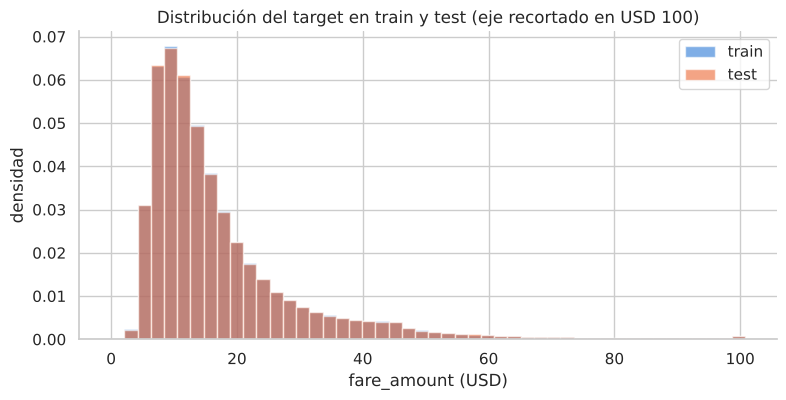

In [44]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 101, 2.1)
ax.hist(train[TARGET].clip(upper=100), bins=bins, density=True, alpha=.6, color=AZUL, label="train")
ax.hist(test[TARGET].clip(upper=100), bins=bins, density=True, alpha=.6, color=NARANJA, label="test")
ax.set(title="Distribución del target en train y test (eje recortado en USD 100)",
       xlabel="fare_amount (USD)", ylabel="densidad")
ax.legend()
FIG_DIR = Path("figures/split"); FIG_DIR.mkdir(parents=True, exist_ok=True)
guardar(fig, "01_split_target"); plt.show()

**Lectura:** media, cuartiles y percentil 99 del target son prácticamente iguales en train y test, y los histogramas se
superponen: la partición aleatoria conserva la distribución del target, por lo que ambos conjuntos son representativos.

**A partir de acá, todo lo que calcule parámetros (imputación, límites de outliers, escalado, encoding, PCA) se
calcula en `train` y se aplica igual en `test`.**

---
# 15. Tratamiento de valores faltantes (calculado en train, aplicado en train y test)
Primer paso de las transformaciones. Los parámetros (la moda) se **calculan solo con train** y se **aplican igual** en
train y test, para no usar información del test.

| # | Variable | Faltantes | Mecanismo (EDA, sección 9) | Tratamiento elegido | Justificación |
|---|---|---|---|---|---|
| 15.1 | `passenger_count` | ~0,3 % (eran ceros → NaN en la sección 12) | **MAR**: se concentra en `VendorID = 1` | **Imputar con la moda de cada `VendorID`**, calculada en train | Al ser MAR, el faltante depende de otra variable observada: se imputa considerando ese patrón (moda dentro de cada grupo). Es discreta y muy concentrada en 1, por eso moda y no media |
| 15.2 | `RatecodeID` | ~3,3 % (eran código 99 → NaN en la sección 12) | **MAR**: casi todos de `VendorID = 1` | **Categoría propia "desconocido"** | Solo ~1,4 % de esas tarifas sigue el patrón del taxímetro estándar (sección 12): imputar la moda (1 = estándar) asumiría algo que los datos contradicen. Una categoría propia no inventa información y permite que el modelo aprenda si ese grupo cobra distinto |
| — | `request_source` | 100 % en la población | **Estructural**: solo existe en viajes Flex Fare, ya excluidos | No se imputa | Columna sin información en la población: se elimina en la selección de features |

In [45]:
# Faltantes en train y test antes del tratamiento (solo columnas con algún NaN)
nan_antes = pd.DataFrame({"NaN train": train.isna().sum(), "% train": train.isna().mean() * 100,
                          "NaN test": test.isna().sum(), "% test": test.isna().mean() * 100})
nan_antes[nan_antes["NaN train"] + nan_antes["NaN test"] > 0]

,NaN train,% train,NaN test,% test
passenger_count,5577,0.315,1425,0.322
RatecodeID,57861,3.269,14468,3.270
request_source,1769722,100.000,442431,100.000


### 15.1 `passenger_count`: moda por proveedor

In [46]:
train = train.copy(); test = test.copy()

# Parámetro aprendido SOLO en train: la moda de passenger_count dentro de cada VendorID
moda_pc_por_vendor = (train.groupby("VendorID", observed=True)["passenger_count"]
                           .agg(lambda s: s.mode().iloc[0]))
print("Moda de passenger_count por VendorID (calculada en train):")
display(moda_pc_por_vendor.to_frame("moda"))

antes_pc = train["passenger_count"].value_counts(normalize=True, dropna=False).mul(100).sort_index()

# Se aplica la misma regla en train y en test
for d in (train, test):
    faltan = d["passenger_count"].isna()
    d.loc[faltan, "passenger_count"] = d.loc[faltan, "VendorID"].map(moda_pc_por_vendor).astype(float)

despues_pc = train["passenger_count"].value_counts(normalize=True, dropna=False).mul(100).sort_index()
pd.DataFrame({"% antes (train)": antes_pc, "% después (train)": despues_pc}).fillna(0)

Moda de passenger_count por VendorID (calculada en train):


,moda
VendorID,
1,1.000
2,1.000


,% antes (train),% después (train)
passenger_count,,
1.000,82.523,82.838
2.000,11.821,11.821
3.000,2.992,2.992
4.000,2.055,2.055
5.000,0.183,0.183
6.000,0.111,0.111
NaN,0.315,0.000


**Lectura:** la moda es 1 pasajero en ambos proveedores, así que los faltantes pasan a 1. Como eran solo el 0,3 %, la
distribución de `passenger_count` prácticamente no cambia: la imputación no distorsiona la variable.

### 15.2 `RatecodeID`: categoría propia "desconocido"

In [47]:
for d in (train, test):
    if "desconocido" not in d["RatecodeID"].cat.categories:
        d["RatecodeID"] = d["RatecodeID"].cat.add_categories("desconocido")
    d["RatecodeID"] = d["RatecodeID"].fillna("desconocido")

pd.DataFrame({"% train": train["RatecodeID"].value_counts(normalize=True).mul(100),
              "% test":  test["RatecodeID"].value_counts(normalize=True).mul(100)})

,% train,% test
RatecodeID,,
1.000,96.330,96.330
desconocido,3.269,3.270
3.000,0.357,0.361
4.000,0.043,0.040


**Lectura:** la categoría "desconocido" queda con ~3 % en train y en test (proporciones similares por ser una partición
aleatoria). Esta categoría no requiere ningún parámetro aprendido; se aplica igual en ambos conjuntos.

In [48]:
# Verificación: faltantes restantes en las variables tratadas
pd.DataFrame({"NaN train": train[["passenger_count", "RatecodeID"]].isna().sum(),
              "NaN test":  test[["passenger_count", "RatecodeID"]].isna().sum()})

,NaN train,NaN test
passenger_count,0,0
RatecodeID,0,0


---
# 16. Tratamiento de outliers (calculado en train)
**Criterio de detección: IQR (método robusto) aplicado sobre log(`fare_amount`).**

| Decisión | Justificación |
|---|---|
| Método **IQR** y no media ± 3 STD | El target es muy asimétrico y con colas pesadas (sección 3): media y desvío están inflados por la cola, por eso el criterio clásico no es adecuado |
| IQR calculado sobre el **logaritmo** del target | El IQR marca como atípico lo que se aleja del 50 % central. Con un target tan asimétrico, el IQR directo (límite ≈ USD 36) marca como "outliers" al 8 % de los viajes, en su mayoría viajes normales de aeropuerto (LaGuardia y JFK a Queens/Brooklyn). En escala log la distribución es casi simétrica y el criterio solo marca los extremos reales |
| **Eliminar** las filas detectadas | Son pocos casos (1,15 % de train) y extremos: se quitan para que no dominen el aprendizaje |
| Solo en **train**; el **test no se filtra** | Para eliminar un outlier hay que conocer su tarifa, que es lo que se quiere predecir. Al cotizar un viaje real esa información no existe, así que el test debe representar viajes reales, incluidos los extremos |
| **El target no se transforma** | El log se usa solo para calcular los límites; luego se vuelven a USD. Las tarifas de los viajes que quedan no cambian |

In [49]:
log_y = np.log(train[TARGET])
q1, q3 = log_y.quantile([.25, .75])
iqr_log = q3 - q1
lim_inf, lim_sup = np.exp(q1 - 1.5 * iqr_log), np.exp(q3 + 1.5 * iqr_log)

es_outlier = (train[TARGET] < lim_inf) | (train[TARGET] > lim_sup)
resumen_out = pd.DataFrame({
    "límite (USD)": [lim_inf, lim_sup],
    "viajes de train fuera del límite": [(train[TARGET] < lim_inf).sum(), (train[TARGET] > lim_sup).sum()],
}, index=["inferior", "superior"])
resumen_out["% de train"] = resumen_out["viajes de train fuera del límite"] / len(train) * 100
display(resumen_out)
print(f"Referencia: con IQR directo (sin log) el límite superior sería USD "
      f"{train[TARGET].quantile(.75) + 1.5 * (train[TARGET].quantile(.75) - train[TARGET].quantile(.25)):.1f} "
      f"y marcaría el {((train[TARGET] > train[TARGET].quantile(.75) + 1.5 * (train[TARGET].quantile(.75) - train[TARGET].quantile(.25)))).mean():.1%} de train.")

,límite (USD),viajes de train fuera del límite,% de train
inferior,2.585,0,0.000
superior,67.168,20343,1.150


Referencia: con IQR directo (sin log) el límite superior sería USD 36.3 y marcaría el 8.2% de train.


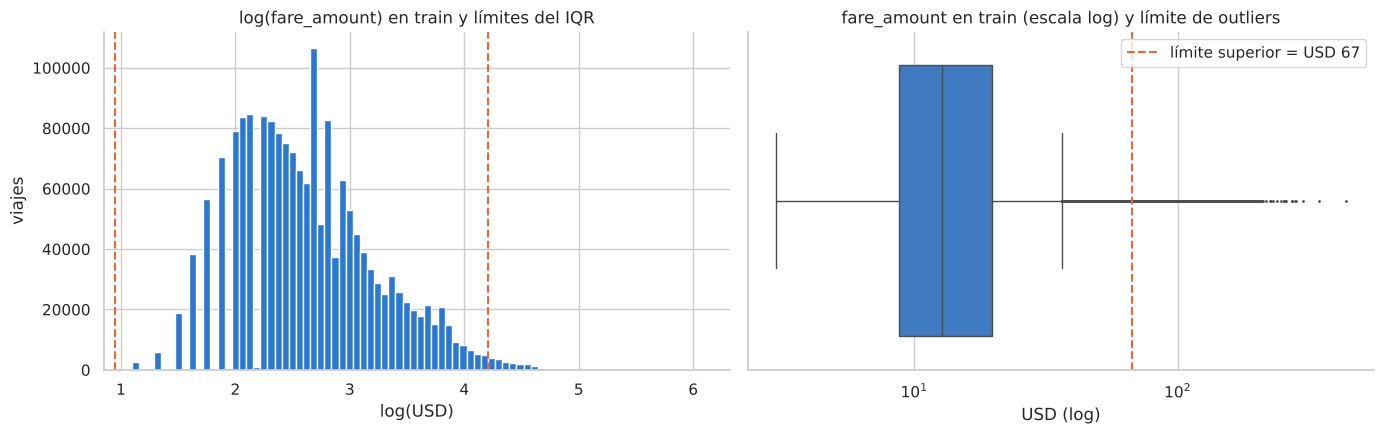

Train: 1,769,722 → 1,749,379 viajes (se eliminaron 20,343 outliers, 1.15%).  Test sin cambios: 442,431 viajes.


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(log_y, bins=80, color=AZUL)
for lim in (q1 - 1.5 * iqr_log, q3 + 1.5 * iqr_log):
    axes[0].axvline(lim, color=NARANJA, ls="--")
axes[0].set(title="log(fare_amount) en train y límites del IQR", xlabel="log(USD)", ylabel="viajes")
sns.boxplot(x=train[TARGET], ax=axes[1], color=AZUL, fliersize=1)
axes[1].axvline(lim_sup, color=NARANJA, ls="--", label=f"límite superior = USD {lim_sup:.0f}")
axes[1].set(xscale="log", title="fare_amount en train (escala log) y límite de outliers", xlabel="USD (log)")
axes[1].legend()
FIG_DIR = Path("figures/preparacion"); FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.tight_layout(); guardar(fig, "01_outliers_limites"); plt.show()

n_antes = len(train)
train = train.loc[~es_outlier].copy()
print(f"Train: {n_antes:,} → {len(train):,} viajes (se eliminaron {n_antes - len(train):,} outliers, "
      f"{(n_antes - len(train)) / n_antes:.2%}).  Test sin cambios: {len(test):,} viajes.")

**Lectura:** los límites en dólares (≈ USD 2,6 y ≈ USD 67) dejan dentro a los viajes de aeropuerto por taxímetro y solo
eliminan alrededor del 1 % de train, correspondiente a los viajes más extremos. Como la tarifa mínima posible es USD 3, el
límite inferior no elimina ningún viaje.

---
# 17. Creación de features
| Feature nueva | Cómo se construye | Técnica | Justificación |
|---|---|---|---|
| `distancia_tipica_od` | **Mediana** de `trip_distance` de cada par **zona de origen – zona de destino**, calculada en train. Si el par tiene menos de 10 viajes en train se usa la mediana del par de **boroughs**, y si tampoco existe, la **mediana global** | Agregado por grupo | La distancia real es el mejor predictor de la tarifa pero es *leakage* (se mide al final). La distancia **típica** de ese recorrido sí se conoce de antemano: es lo que una app estima antes del viaje. Para combinaciones raras se usa un nivel más agregado, para no basarse en muy pocos datos |
| `origen_aeropuerto`, `destino_aeropuerto` | 1 si la zona es JFK, LaGuardia o Newark | Conocimiento del dominio | Los viajes de aeropuerto son un régimen tarifario propio (secciones 5, 10 y 16) |
| `fin_de_semana` | 1 si el pickup es sábado o domingo | Temporal | Patrón distinto de demanda entre días hábiles y fin de semana (sección 6) |

La mediana (y no la media) porque la distancia es muy asimétrica con valores extremos (sección 4): es una medida robusta.

In [51]:
AEROPUERTOS = [1, 132, 138]          # Newark, JFK, LaGuardia (tabla de zonas TLC)
MIN_VIAJES_PAR = 10

# Parámetros aprendidos SOLO en train
g_par = (train.groupby(["PULocationID", "DOLocationID"], observed=True)["trip_distance"]
              .agg(mediana="median", viajes="size").reset_index())
g_par = g_par[g_par["viajes"] >= MIN_VIAJES_PAR]
g_bor = (train.groupby(["PU_borough", "DO_borough"], observed=True)["trip_distance"]
              .median().rename("med_borough").reset_index())
mediana_global = train["trip_distance"].median()

def agregar_features(d):
    d = d.copy()
    d["origen_aeropuerto"] = d["PULocationID"].astype(int).isin(AEROPUERTOS).astype(int)
    d["destino_aeropuerto"] = d["DOLocationID"].astype(int).isin(AEROPUERTOS).astype(int)
    d["fin_de_semana"] = (d["dia_semana"] >= 5).astype(int)
    d = d.merge(g_par[["PULocationID", "DOLocationID", "mediana"]], on=["PULocationID", "DOLocationID"], how="left")
    d = d.merge(g_bor, on=["PU_borough", "DO_borough"], how="left")
    d["fuente_distancia"] = np.where(d["mediana"].notna(), "par de zonas",
                             np.where(d["med_borough"].notna(), "par de boroughs", "global"))
    d["distancia_tipica_od"] = d["mediana"].fillna(d["med_borough"]).fillna(mediana_global)
    return d.drop(columns=["mediana", "med_borough"])

train = agregar_features(train)
test = agregar_features(test)

pd.DataFrame({"% train": train["fuente_distancia"].value_counts(normalize=True) * 100,
              "% test": test["fuente_distancia"].value_counts(normalize=True) * 100}).fillna(0)

,% train,% test
fuente_distancia,,
global,0.000,0.013
par de boroughs,1.556,2.176
par de zonas,98.444,97.811


In [52]:
from scipy import stats
rel = pd.DataFrame({
    "Spearman con fare_amount (train)": [stats.spearmanr(train["trip_distance"], train[TARGET])[0],
                                        stats.spearmanr(train["distancia_tipica_od"], train[TARGET])[0]],
    "¿se conoce al subir?": ["No (leakage)", "Sí"],
}, index=["trip_distance (real)", "distancia_tipica_od (nueva)"])
rel

,Spearman con fare_amount (train),¿se conoce al subir?
trip_distance (real),0.918,No (leakage)
distancia_tipica_od (nueva),0.845,Sí


**Lectura:** casi todos los viajes reciben la distancia típica de su propio par de zonas (las combinaciones raras son
pocas). La nueva feature conserva gran parte de la relación con la tarifa que tenía la distancia real, pero **sin
leakage**: es información disponible al momento de cotizar.

---
# 18. Discretización
**`hora` → `franja_horaria`** con puntos de corte definidos por **conocimiento del dominio** (ancho fijo):
madrugada (0–5 h), mañana (6–11 h), tarde (12–17 h), noche (18–23 h).

**Justificación:** las secciones 6 y 7.2 mostraron que la hora explica muy poco de la tarifa por sí sola pero el comportamiento cambia
por bloques del día (madrugada con viajes más largos, tarde con mayor demanda). Agrupar reduce ruido y mejora la
interpretación. La hora también se conserva con codificación cíclica (sección 19); la selección de features (sección 22)
decide cuál representación aporta más.

In [53]:
cortes = [-1, 5, 11, 17, 23]
franjas = ["madrugada", "mañana", "tarde", "noche"]
for d in (train, test):
    d["franja_horaria"] = pd.cut(d["hora"], bins=cortes, labels=franjas)

train.groupby("franja_horaria", observed=True)[TARGET].agg(viajes="size", mediana="median", media="mean")

,viajes,mediana,media
franja_horaria,,,
madrugada,135653,13.500,17.177
mañana,369754,12.760,15.913
tarde,650437,12.800,16.333
noche,593535,12.800,16.252


**Lectura:** la madrugada concentra menos viajes y con tarifa mediana algo más alta (viajes más largos); en el resto del
día la tarifa mediana es prácticamente igual. La discretización resume ese patrón en 4 categorías; la sección 22 evalúa
si aporta relevancia predictiva.

---
# 19. Codificación de variables categóricas
Se codifican solo las variables **candidatas a feature** (sección 7.3); las que se descartan por leakage, irrelevancia o
falta de variación se documentan en la sección 22 (criterio A).

| Variable | Cardinalidad | Codificación | Justificación |
|---|---|---|---|
| `PULocationID`, `DOLocationID` | ~260 | **Target encoding con k-fold (5 folds)** | Alta cardinalidad en un problema supervisado: one-hot generaría cientos de columnas. Se reemplaza cada zona por la tarifa media de esa zona; para evitar sobreajuste (*leakage* del propio target) se calcula con k-fold sobre train y se aplica a test con los valores de train |
| `RatecodeID` (1, 3, 4, desconocido), `PU_borough`, `DO_borough`, `franja_horaria` | 4 a 6 | **One-hot** | Baja cardinalidad y nominales: una columna 0/1 por categoría |
| `VendorID` | 2 | **One-hot binaria** (una sola columna 0/1) | Variable binaria |
| `hora`, `dia_semana` | 24 y 7 | **Codificación cíclica** (seno y coseno) | Son cíclicas: las 23 h están cerca de las 0 h y el domingo del lunes |
| `origen_aeropuerto`, `destino_aeropuerto`, `fin_de_semana` | 2 | Ya son 0/1 | — |

Categorías que aparezcan en test y no en train se codifican con ceros (one-hot) o con la media global (target encoding).

In [54]:
from sklearn.preprocessing import TargetEncoder, OneHotEncoder

# --- Target encoding (k-fold) de las zonas: se ajusta en train y se aplica a test ---
te = TargetEncoder(target_type="continuous", cv=5, smooth="auto", random_state=SEED)
zonas_cols = ["PULocationID", "DOLocationID"]
te_train = te.fit_transform(train[zonas_cols].astype(int), train[TARGET])   # k-fold dentro de train
te_test = te.transform(test[zonas_cols].astype(int))                        # valores aprendidos en train

# --- One-hot de categóricas de baja cardinalidad ---
oh_cols = ["RatecodeID", "PU_borough", "DO_borough", "franja_horaria", "VendorID"]
ohe = OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False)
oh_train = ohe.fit_transform(train[oh_cols].astype(str))
oh_test = ohe.transform(test[oh_cols].astype(str))
oh_nombres = [n.replace(".0", "") for n in ohe.get_feature_names_out(oh_cols)]

# --- Codificación cíclica ---
def ciclica(d):
    return pd.DataFrame({"hora_sin": np.sin(2 * np.pi * d["hora"] / 24), "hora_cos": np.cos(2 * np.pi * d["hora"] / 24),
                         "dia_sin": np.sin(2 * np.pi * d["dia_semana"] / 7), "dia_cos": np.cos(2 * np.pi * d["dia_semana"] / 7)},
                        index=d.index)

def armar_X(d, te_vals, oh_vals):
    X = pd.DataFrame({"passenger_count": d["passenger_count"].values,
                      "distancia_tipica_od": d["distancia_tipica_od"].values,
                      "PU_target_enc": te_vals[:, 0], "DO_target_enc": te_vals[:, 1],
                      "origen_aeropuerto": d["origen_aeropuerto"].values,
                      "destino_aeropuerto": d["destino_aeropuerto"].values,
                      "fin_de_semana": d["fin_de_semana"].values})
    X = pd.concat([X, ciclica(d).reset_index(drop=True), pd.DataFrame(oh_vals, columns=oh_nombres)], axis=1)
    return X

X_train = armar_X(train.reset_index(drop=True), te_train, oh_train)
X_test = armar_X(test.reset_index(drop=True), te_test, oh_test)
y_train = train[TARGET].reset_index(drop=True)
y_test = test[TARGET].reset_index(drop=True)

print(f"X_train: {X_train.shape}  |  X_test: {X_test.shape}")
X_train.head()

X_train: (1749379, 31)  |  X_test: (442431, 31)


,passenger_count,distancia_tipica_od,PU_target_enc,DO_target_enc,origen_aeropuerto,destino_aeropuerto,fin_de_semana,hora_sin,hora_cos,dia_sin,dia_cos,RatecodeID_1,RatecodeID_3,RatecodeID_4,RatecodeID_desconocido,PU_borough_Bronx,PU_borough_Brooklyn,PU_borough_Manhattan,PU_borough_Queens,PU_borough_Staten Island,DO_borough_Bronx,DO_borough_Brooklyn,DO_borough_EWR,DO_borough_Manhattan,DO_borough_Queens,DO_borough_Staten Island,franja_horaria_madrugada,franja_horaria_mañana,franja_horaria_noche,franja_horaria_tarde,VendorID_2
0,1.000,2.510,14.343,13.293,0,0,0,-0.966,-0.259,0.782,0.623,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000
1,2.000,1.725,14.527,16.507,0,0,0,-0.707,-0.707,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000
2,1.000,1.680,14.530,12.688,0,0,0,-0.866,-0.500,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000
3,1.000,2.290,12.222,12.931,0,0,0,-0.866,-0.500,0.782,0.623,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000
4,1.000,0.545,12.709,13.942,0,0,0,-0.966,0.259,-0.434,-0.901,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000


In [55]:
# Ejemplo de target encoding: zonas de origen con mayor y menor tarifa codificada
ej = (pd.DataFrame({"zona": train["PU_zona"].values, "PU_target_enc": X_train["PU_target_enc"]})
        .groupby("zona", observed=True)["PU_target_enc"].mean().sort_values())
pd.concat([ej.head(3), ej.tail(3)]).to_frame("tarifa codificada (USD)")

,tarifa codificada (USD)
zona,
Arrochar/Fort Wadsworth,11.076
Upper East Side South,12.228
Lenox Hill West,12.367
LaGuardia Airport,40.959
Rikers Island,41.492
Great Kills,53.165


**Lectura:** el target encoding transforma ~260 categorías en **una sola columna numérica** por variable, que resume la
tarifa típica de cada zona (por ejemplo, las zonas de aeropuerto quedan con valores altos). Con one-hot habrían sido más
de 500 columnas.

---
# 20. Escalado
**Estandarización (z-score)**: media 0 y desvío 1, con parámetros calculados en train y aplicados a test.

| Columnas | ¿Se escalan? | Justificación |
|---|---|---|
| `passenger_count`, `distancia_tipica_od` | **Sí** | Numéricas en escalas distintas |
| `PU_target_enc`, `DO_target_enc` | **Sí** | Las variables con target encoding se escalan igual que las numéricas |
| One-hot y binarias (0/1) | **No** | Escalarlas no aporta nada |
| Cíclicas (seno, coseno) | **No** | Escalarlas rompería el efecto cíclico |

Se elige estandarización (y no normalización min–max) porque es la que requiere el PCA de la sección 23.

In [56]:
from sklearn.preprocessing import StandardScaler

a_escalar = ["passenger_count", "distancia_tipica_od", "PU_target_enc", "DO_target_enc"]
scaler = StandardScaler().fit(X_train[a_escalar])          # parámetros SOLO de train
X_train[a_escalar] = scaler.transform(X_train[a_escalar])
X_test[a_escalar] = scaler.transform(X_test[a_escalar])

pd.DataFrame({"media train": X_train[a_escalar].mean(), "desvío train": X_train[a_escalar].std(),
              "media test": X_test[a_escalar].mean(), "desvío test": X_test[a_escalar].std()})

,media train,desvío train,media test,desvío test
passenger_count,-0.000,1.000,0.003,1.003
distancia_tipica_od,-0.000,1.000,0.043,1.081
PU_target_enc,-0.000,1.000,0.027,1.040
DO_target_enc,-0.000,1.000,0.042,1.092


**Lectura:** en train las columnas escaladas quedan con media 0 y desvío 1. En test quedan **cerca** de 0 y 1 pero no
exactos, porque se aplican los parámetros de train: es lo esperado y confirma que no se usó información de test.

---
# 21. Balanceo de clases: no aplica
El desbalance es una característica de los problemas de **clasificación** (cuando una clase del target tiene muchas más
observaciones que otra). Este es un problema de **regresión**: el target es numérico continuo y no tiene clases, por lo
que no se aplican técnicas de balanceo (oversampling, undersampling, etc.).

---
# 22. Selección de features
Se aplican los cuatro criterios de selección: **(A)** features irrelevantes, no disponibles o no confiables;
**(B)** features redundantes; **(C)** features con relación demasiado fuerte con el target; **(D)** relevancia predictiva.

### 22 (A) Irrelevantes, no disponibles o no confiables — criterio y conocimiento del dominio
| Variables descartadas | Motivo | Evidencia |
|---|---|---|
| `trip_distance`, `tpep_dropoff_datetime` (duración), `tip_amount`, `tolls_amount`, `total_amount`, `payment_type` | **No disponibles al predecir** (se conocen al final del viaje o al pagar) | Sección 7.3 |
| `extra`, `congestion_surcharge`, `cbd_congestion_fee` | No disponibles o dependientes del recorrido; asociación débil | Sección 7.3 |
| `Airport_fee` | Redundante: ya está en la zona de origen y en `origen_aeropuerto` | Sección 7.3 (~97 % coincide con JFK/LaGuardia) |
| `mta_tax`, `improvement_surcharge` | Casi constantes: no aportan variación | Sección 4 |
| `store_and_fwd_flag` | Dato técnico de transmisión, irrelevante para el fenómeno | Sección 1 |
| `request_source` | Vacía en toda la población (solo existía en Flex Fare) | Sección 15 |
| `tpep_pickup_datetime` | Se usa a través de sus derivadas (hora, día, fin de semana, franja) | Sección 13 |
| Columnas descriptivas (`PU_zona`, `DO_zona`, `PU_servicio`, `DO_servicio`, `fuente_distancia`) | Solo para interpretar: su información ya está en las zonas codificadas y en los boroughs | Sección 13 y 17 |

Las features que quedan como candidatas son las de `X_train`.

In [57]:
print(f"Features candidatas: {X_train.shape[1]}")
print(list(X_train.columns))

Features candidatas: 31
['passenger_count', 'distancia_tipica_od', 'PU_target_enc', 'DO_target_enc', 'origen_aeropuerto', 'destino_aeropuerto', 'fin_de_semana', 'hora_sin', 'hora_cos', 'dia_sin', 'dia_cos', 'RatecodeID_1', 'RatecodeID_3', 'RatecodeID_4', 'RatecodeID_desconocido', 'PU_borough_Bronx', 'PU_borough_Brooklyn', 'PU_borough_Manhattan', 'PU_borough_Queens', 'PU_borough_Staten Island', 'DO_borough_Bronx', 'DO_borough_Brooklyn', 'DO_borough_EWR', 'DO_borough_Manhattan', 'DO_borough_Queens', 'DO_borough_Staten Island', 'franja_horaria_madrugada', 'franja_horaria_mañana', 'franja_horaria_noche', 'franja_horaria_tarde', 'VendorID_2']


### 22 (B) Features redundantes — asociación entre features
Se calcula la correlación de Spearman entre todas las features candidatas (en train). Un par con |ρ| ≥ 0,8 indica que
ambas aportan casi la misma información: se conserva la de mayor relevancia predictiva (criterio D).

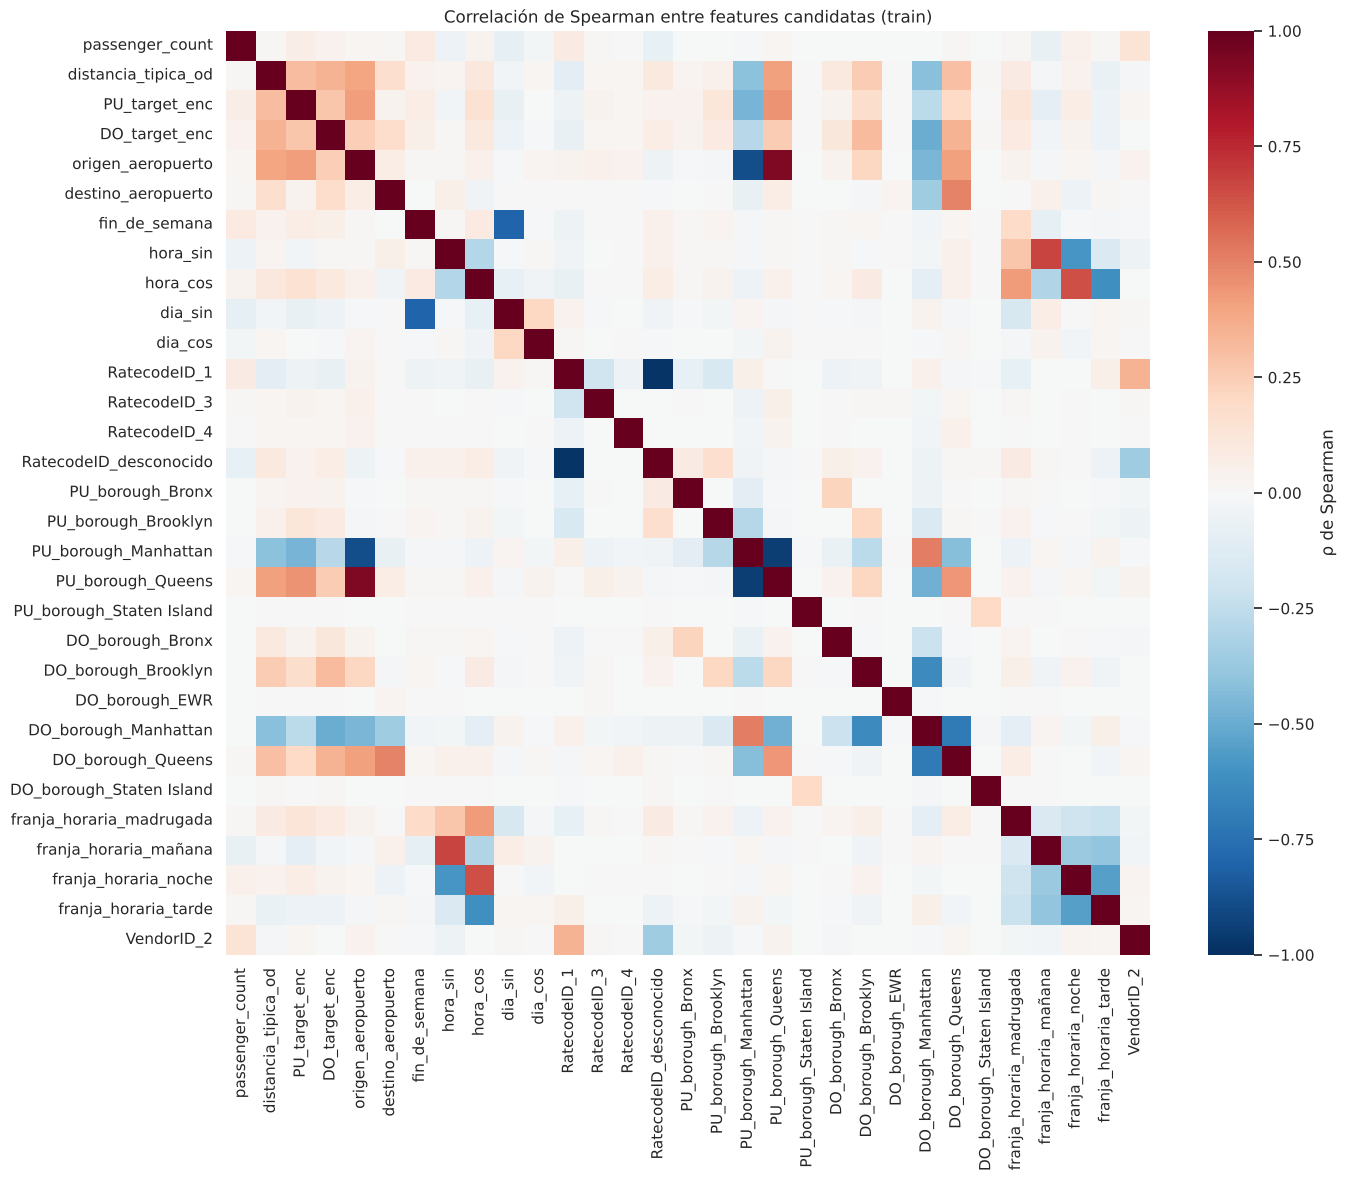

,feature A,feature B,rho
355,RatecodeID_1,RatecodeID_desconocido,-0.977
545,PU_borough_Manhattan,PU_borough_Queens,-0.946
142,origen_aeropuerto,PU_borough_Queens,0.935
141,origen_aeropuerto,PU_borough_Manhattan,-0.884
195,fin_de_semana,dia_sin,-0.800


In [58]:
corr_X = X_train.corr(method="spearman")
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr_X, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, square=True, cbar_kws={"label": "ρ de Spearman"})
ax.set_title("Correlación de Spearman entre features candidatas (train)")
guardar(fig, "02_corr_features"); plt.show()

pares = (corr_X.where(np.triu(np.ones(corr_X.shape, dtype=bool), k=1)).stack()
              .rename("rho").reset_index().rename(columns={"level_0": "feature A", "level_1": "feature B"}))
redundantes = pares[pares["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False)
redundantes

### 22 (C) Relación demasiado fuerte con el target
Una asociación muy fuerte puede indicar que la feature "revela" el target (*leakage*). Se mide Spearman de cada
feature con `fare_amount` en train.

In [59]:
rho_target = X_train.apply(lambda c: stats.spearmanr(c, y_train)[0]).rename("ρ con fare_amount")
rho_target.to_frame().sort_values("ρ con fare_amount", key=abs, ascending=False).head(8)

,ρ con fare_amount
distancia_tipica_od,0.845
DO_borough_Manhattan,-0.377
PU_borough_Queens,0.376
PU_borough_Manhattan,-0.374
origen_aeropuerto,0.370
DO_target_enc,0.352
PU_target_enc,0.332
DO_borough_Queens,0.258


**Lectura:** la feature más asociada es `distancia_tipica_od`. Su asociación es fuerte pero **no es leakage**: se
construyó solo con información disponible antes del viaje (la distancia típica histórica del recorrido, calculada en
train). Las variables que sí revelaban el target (distancia real, duración, total cobrado) ya se descartaron en el criterio A.

### 22 (D) Relevancia predictiva — información mutua y correlación
Se usan dos métodos y se comparan sus resultados normalizados (0 = menos relevante, 1 = más relevante):
- **Información mutua** (`mutual_info_regression`): mide cuánto se reduce la incertidumbre del target al conocer la
  feature; capta relaciones no lineales. Se calcula sobre una muestra aleatoria de 200.000 viajes de train (fija con la
  semilla) porque su estimación es costosa.
- **|ρ de Spearman|** con el target (sección C).

Recordar: para variables codificadas con one-hot o cíclica, el puntaje es **por columna** (por categoría o por
componente), no de la variable completa.

In [60]:
from sklearn.feature_selection import mutual_info_regression

idx = X_train.sample(200_000, random_state=SEED).index
binarias = [c for c in X_train.columns if set(np.unique(X_train[c])) <= {0, 1}]
mi = mutual_info_regression(X_train.loc[idx], y_train.loc[idx],
                            discrete_features=[c in binarias for c in X_train.columns], random_state=SEED)

relevancia = pd.DataFrame({"información mutua": mi, "|ρ Spearman|": rho_target.abs().values}, index=X_train.columns)
for c in ["información mutua", "|ρ Spearman|"]:
    relevancia[c + " (norm.)"] = relevancia[c] / relevancia[c].max()
relevancia["puntaje combinado"] = relevancia[["información mutua (norm.)", "|ρ Spearman| (norm.)"]].mean(axis=1)
relevancia = relevancia.sort_values("puntaje combinado", ascending=False)
relevancia

,información mutua,|ρ Spearman|,información mutua (norm.),|ρ Spearman| (norm.),puntaje combinado
distancia_tipica_od,0.820,0.845,1.000,1.000,1.000
DO_target_enc,0.186,0.352,0.227,0.416,0.321
PU_target_enc,0.165,0.332,0.201,0.393,0.297
PU_borough_Queens,0.116,0.376,0.142,0.445,0.293
PU_borough_Manhattan,0.115,0.374,0.140,0.443,0.291
origen_aeropuerto,0.112,0.370,0.136,0.437,0.287
DO_borough_Manhattan,0.101,0.377,0.123,0.446,0.285
DO_borough_Queens,0.046,0.258,0.056,0.305,0.180
DO_borough_Brooklyn,0.043,0.247,0.052,0.293,0.173
RatecodeID_1,0.139,0.103,0.169,0.122,0.146


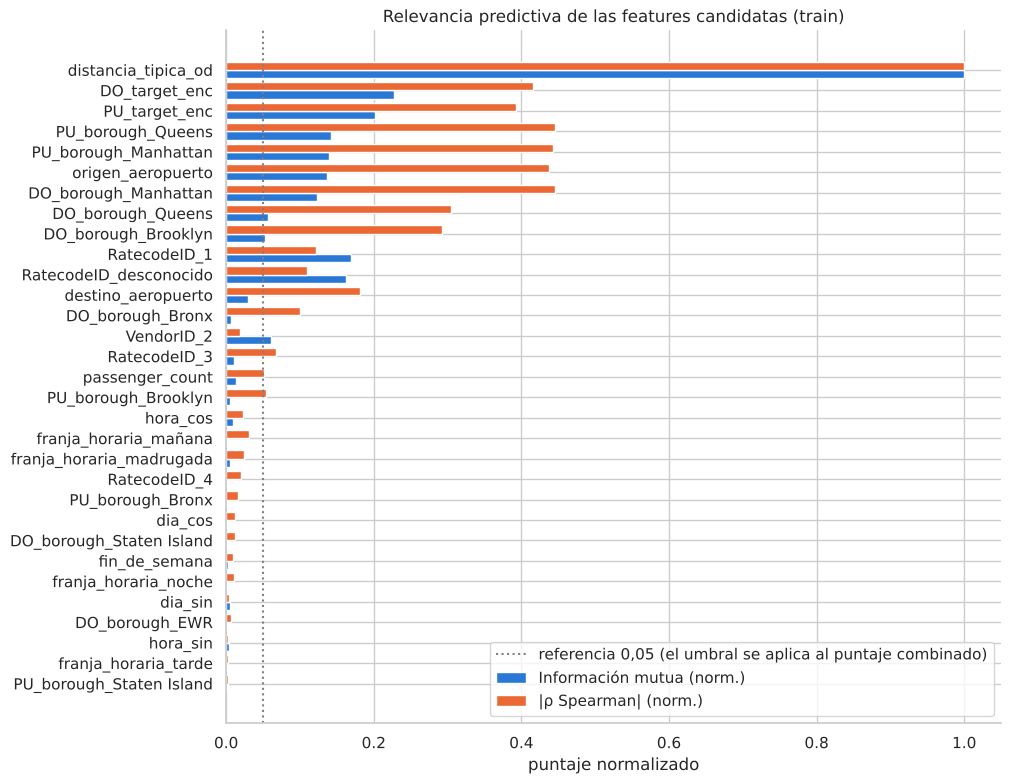

In [61]:
fig, ax = plt.subplots(figsize=(10, 9))
d = relevancia.sort_values("puntaje combinado")
y_pos = np.arange(len(d))
ax.barh(y_pos - 0.2, d["información mutua (norm.)"], height=0.4, color=AZUL, label="Información mutua (norm.)")
ax.barh(y_pos + 0.2, d["|ρ Spearman| (norm.)"], height=0.4, color=NARANJA, label="|ρ Spearman| (norm.)")
ax.set_yticks(y_pos); ax.set_yticklabels(d.index)
ax.axvline(0.05, color="gray", ls=":", label="referencia 0,05 (el umbral se aplica al puntaje combinado)")
ax.set(title="Relevancia predictiva de las features candidatas (train)", xlabel="puntaje normalizado")
ax.legend(loc="lower right")
guardar(fig, "03_relevancia_features"); plt.show()

### Criterio de reducción
1. Se descartan las features con **puntaje combinado < 0,05** (relevancia predictiva casi nula en ambos métodos).
2. De cada par **redundante** (|ρ| ≥ 0,8 entre features) se conserva la de mayor puntaje combinado.

In [62]:
UMBRAL = 0.05
baja_relevancia = relevancia.index[relevancia["puntaje combinado"] < UMBRAL].tolist()

descartar_redundantes = []
for _, fila in redundantes.iterrows():
    a, b = fila["feature A"], fila["feature B"]
    if a in descartar_redundantes or b in descartar_redundantes:
        continue
    peor = a if relevancia.loc[a, "puntaje combinado"] < relevancia.loc[b, "puntaje combinado"] else b
    descartar_redundantes.append(peor)

descartadas = sorted(set(baja_relevancia) | set(descartar_redundantes))
seleccionadas = [c for c in X_train.columns if c not in descartadas]

print(f"Descartadas por baja relevancia ({len(baja_relevancia)}): {baja_relevancia}")
print(f"Descartadas por redundancia ({len(descartar_redundantes)}): {descartar_redundantes}")
print(f"\nFeatures seleccionadas ({len(seleccionadas)} de {X_train.shape[1]}): {seleccionadas}")

X_train_sel = X_train[seleccionadas]
X_test_sel = X_test[seleccionadas]

Descartadas por baja relevancia (18): ['VendorID_2', 'RatecodeID_3', 'passenger_count', 'PU_borough_Brooklyn', 'hora_cos', 'franja_horaria_mañana', 'franja_horaria_madrugada', 'RatecodeID_4', 'PU_borough_Bronx', 'dia_cos', 'DO_borough_Staten Island', 'fin_de_semana', 'franja_horaria_noche', 'dia_sin', 'DO_borough_EWR', 'hora_sin', 'franja_horaria_tarde', 'PU_borough_Staten Island']
Descartadas por redundancia (4): ['RatecodeID_desconocido', 'PU_borough_Manhattan', 'origen_aeropuerto', 'dia_sin']

Features seleccionadas (10 de 31): ['distancia_tipica_od', 'PU_target_enc', 'DO_target_enc', 'destino_aeropuerto', 'RatecodeID_1', 'PU_borough_Queens', 'DO_borough_Bronx', 'DO_borough_Brooklyn', 'DO_borough_Manhattan', 'DO_borough_Queens']


---
# 23. Extracción de features: PCA (Análisis de Componentes Principales)
PCA transforma las features en un nuevo sistema de ejes (**componentes principales**) ordenados de mayor a menor según la
**varianza** que capturan (autovalores de la matriz de covarianza). Para reducir dimensionalidad se conservan los
primeros *k* componentes.

- **Datos de entrada:** las features seleccionadas, **estandarizadas** (PCA compara varianzas, así que todas las columnas
  deben estar en la misma escala). A diferencia de la sección 20, acá se estandarizan **también las one-hot y binarias**:
  si quedaran en escala 0/1 su varianza sería muy distinta a la del resto y PCA las ponderaría de forma arbitraria.
  La estandarización se ajusta en train y se aplica a test.
- **Criterio para elegir k:** el **método del codo** (sumar más componentes ya no aporta mucho) y el criterio estándar de
  conservar los primeros componentes que acumulen **entre el 70 % y el 80 % de la varianza total**.

In [63]:
from sklearn.decomposition import PCA

esc_pca = StandardScaler().fit(X_train_sel)
Z_train = esc_pca.transform(X_train_sel)
Z_test = esc_pca.transform(X_test_sel)

pca = PCA(random_state=SEED).fit(Z_train)
var_exp = pca.explained_variance_ratio_
var_acum = np.cumsum(var_exp)
k70 = int(np.argmax(var_acum >= 0.70) + 1)
k80 = int(np.argmax(var_acum >= 0.80) + 1)

tabla_pca = pd.DataFrame({"autovalor": pca.explained_variance_, "% varianza": var_exp * 100,
                          "% acumulado": var_acum * 100},
                         index=[f"PC{i+1}" for i in range(len(var_exp))])
print(f"Componentes para acumular el 70 % de la varianza: {k70} de {len(var_exp)}")
print(f"Componentes para acumular el 80 % de la varianza: {k80} de {len(var_exp)}")
tabla_pca.head(12)

Componentes para acumular el 70 % de la varianza: 4 de 10
Componentes para acumular el 80 % de la varianza: 4 de 10


,autovalor,% varianza,% acumulado
PC1,4.294,42.940,42.940
PC2,1.404,14.040,56.980
PC3,1.285,12.848,69.828
PC4,1.035,10.347,80.175
PC5,0.957,9.573,89.749
PC6,0.557,5.572,95.320
PC7,0.286,2.863,98.183
PC8,0.127,1.268,99.451
PC9,0.055,0.546,99.997
PC10,0.000,0.003,100.000


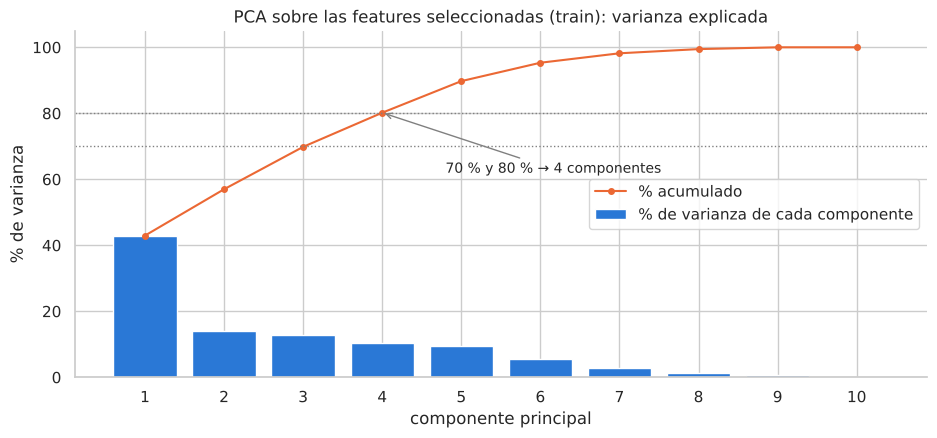

In [64]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(1, len(var_exp) + 1)
ax.bar(x, var_exp * 100, color=AZUL, label="% de varianza de cada componente")
ax.plot(x, var_acum * 100, color=NARANJA, marker="o", ms=4, label="% acumulado")
for p in (70, 80):
    ax.axhline(p, color="gray", ls=":", lw=1)
etiqueta = (f"70 % y 80 % → {k80} componentes" if k70 == k80
            else f"70 % → {k70} componentes · 80 % → {k80} componentes")
ax.annotate(etiqueta, xy=(k80, var_acum[k80 - 1] * 100), xytext=(k80 + 0.8, 62), fontsize=10,
            arrowprops=dict(arrowstyle="->", color="gray"))
ax.set(title="PCA sobre las features seleccionadas (train): varianza explicada", xlabel="componente principal",
       ylabel="% de varianza", xticks=x)
ax.legend(loc="center right")
guardar(fig, "04_pca_varianza"); plt.show()

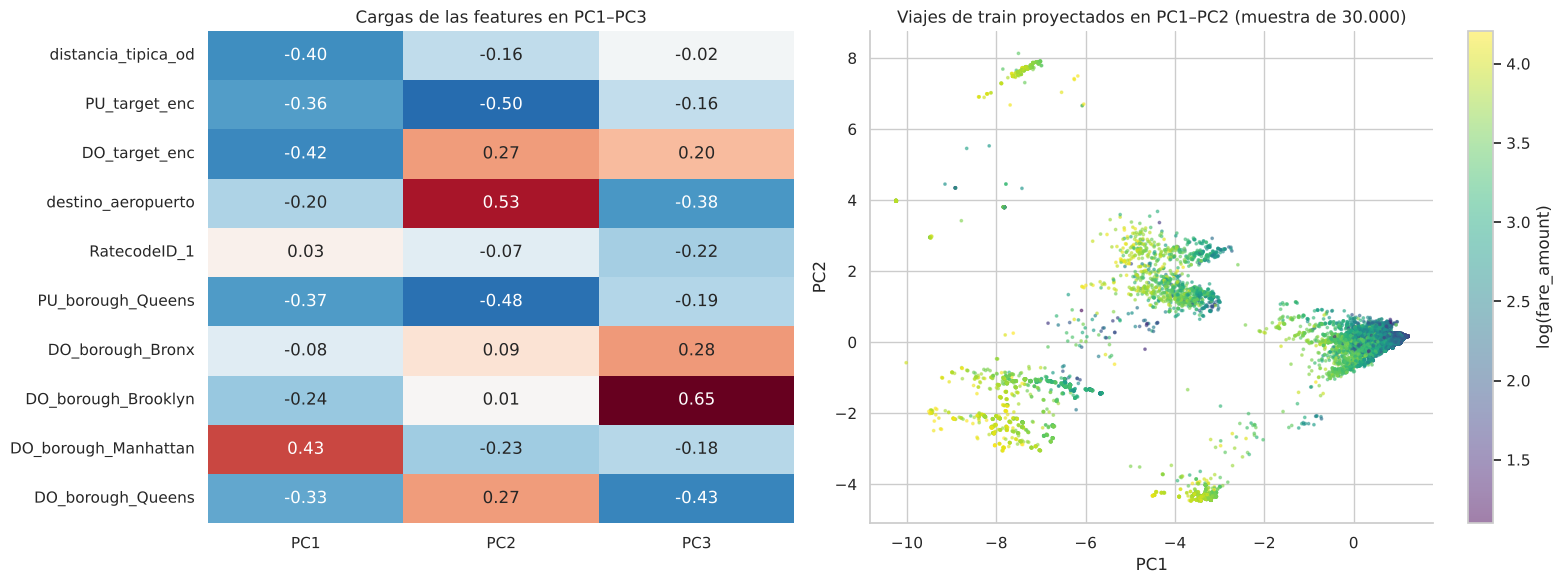

In [65]:
# Cargas (loadings): cuánto aporta cada feature a los primeros componentes
cargas = pd.DataFrame(pca.components_[:3].T, index=X_train_sel.columns, columns=["PC1", "PC2", "PC3"])
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.2]})
sns.heatmap(cargas, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=axes[0], cbar=False)
axes[0].set_title("Cargas de las features en PC1–PC3")

m = np.random.default_rng(SEED).choice(len(Z_train), 30_000, replace=False)
proy = pca.transform(Z_train[m])[:, :2]
sc = axes[1].scatter(proy[:, 0], proy[:, 1], c=np.log(y_train.values[m]), cmap="viridis", s=3, alpha=.5)
axes[1].set(title="Viajes de train proyectados en PC1–PC2 (muestra de 30.000)", xlabel="PC1", ylabel="PC2")
fig.colorbar(sc, ax=axes[1], label="log(fare_amount)")
plt.tight_layout(); guardar(fig, "05_pca_cargas_proyeccion"); plt.show()

In [66]:
pca_k = PCA(n_components=k80, random_state=SEED).fit(Z_train)
X_train_pca = pca_k.transform(Z_train)
X_test_pca = pca_k.transform(Z_test)
print(f"Dataset reducido con PCA: train {X_train_pca.shape}, test {X_test_pca.shape} "
      f"({pca_k.explained_variance_ratio_.sum():.1%} de la varianza)")

Dataset reducido con PCA: train (1749379, 4), test (442431, 4) (80.2% de la varianza)


### Ventajas y desventajas de la reducción con PCA en este dataset
| Ventajas | Desventajas |
|---|---|
| Menos dimensiones conservando la mayor parte de la varianza (criterio 70–80 %) | Se pierde información (la varianza de los componentes descartados) |
| Los componentes no están correlacionados entre sí: elimina la redundancia (por ejemplo, entre zona codificada, borough y aeropuerto) | Los componentes son combinaciones de features: cuesta interpretarlos (¿qué significa "PC2"?) |
| Útil para visualizar en 2D la estructura de los viajes (proyección PC1–PC2) | Muchas features son 0/1 (one-hot): PCA capta varianza, no necesariamente relación con el target |
| Reduce costo computacional para modelos posteriores | Su efectividad depende del dataset y del problema |

**Lectura del resultado:** con **4 componentes se retiene el ~80 % de la varianza** de las 10 features seleccionadas
(reducción de 10 a 4 dimensiones). PC1 concentra ~43 % y combina distancia típica, zonas codificadas y boroughs: resume
"qué tan largo / periférico es el recorrido". El último componente tiene autovalor ≈ 0: las columnas one-hot de borough de
destino son casi linealmente dependientes (si un viaje no va a Bronx, Brooklyn ni Queens, casi seguro va a Manhattan),
y PCA lo detecta como una dirección sin varianza. En la proyección PC1–PC2 los viajes más caros (color claro) se ubican
hacia un extremo de PC1, lo que confirma que el primer componente está ligado a la tarifa.

**Decisión:** se entregan **dos versiones** del dataset preparado: `X_train_sel` / `X_test_sel` (features
seleccionadas, interpretables) y `X_train_pca` / `X_test_pca` (componentes principales). Para un primer modelo se
recomienda la versión con features seleccionadas, por su interpretabilidad; la versión PCA queda como alternativa si la
dimensionalidad o la correlación entre features afectaran al modelo.

---
# 24. Conclusiones

In [67]:
resumen_final = pd.DataFrame({
    "valor": [f"{n_original:,}", f"{len(train) + len(test) + int(es_outlier.sum()):,}", f"{len(train):,}", f"{len(test):,}",
              X_train.shape[1], len(seleccionadas), k80],
}, index=["viajes originales", "viajes tras limpieza y población", "viajes en train (sin outliers)", "viajes en test",
          "features candidatas", "features seleccionadas", "componentes PCA (80 % varianza)"])
resumen_final

,valor
viajes originales,"3,336,716"
viajes tras limpieza y población,"2,212,153"
viajes en train (sin outliers),"1,749,379"
viajes en test,"442,431"
features candidatas,31
features seleccionadas,10
componentes PCA (80 % varianza),4


1. **El dataset crudo no es directamente utilizable.** Un 27,6 % de los viajes del dataset crudo (Flex Fare) sigue otra lógica de precio,
   con 5 columnas vacías por diseño, y hay ~6 % de registros con errores imposibles (duraciones negativas, distancias cero,
   tarifas negativas). Definir bien la **población** (viajes de calle con tarifa de taxímetro) fue tan importante como limpiar.
2. **El target es asimétrico y escalonado.** La tarifa crece en saltos de USD 0,70 y tiene una cola larga de viajes de
   aeropuerto. La **estadística robusta** (mediana, IQR, Spearman) describió mucho mejor los datos que la clásica: un
   puñado de valores absurdos llevaba la curtosis a más de 5.000 y anulaba a Pearson (para `trip_distance`: ρ de Spearman 0,79 vs r de Pearson 0,01).
3. **Las variables más asociadas al precio no se pueden usar.** Distancia, duración y total cobrado explican casi todo el
   target, pero se conocen al final del viaje (*leakage*). La solución fue crear `distancia_tipica_od`, la distancia
   típica histórica de cada recorrido, que se conoce antes de viajar.
4. **El "dónde" importa más que el "cuándo".** Zonas de origen y destino y tipo de tarifa tienen efecto fuerte
   (η² 0,26–0,36); hora, día y pasajeros casi no explican la tarifa por sí solos.
5. **Los outliers no son todos errores.** El IQR directo marcaba como atípicos a viajes normales de aeropuerto; aplicado
   sobre el logaritmo solo marcó el 1,15 % más extremo. Analizar *quiénes* son los outliers antes de eliminarlos cambió la decisión.
6. **Con millones de datos, la significancia no discrimina.** Todos los tests (ANOVA, χ²) dieron p ≈ 0; las decisiones
   se basaron en el **tamaño del efecto** (η², V de Cramér, ρ).
7. **La selección de features confirmó el EDA.** De 31 features candidatas quedaron 10: distancia típica, zonas
   codificadas, tipo de tarifa, aeropuerto y boroughs. Todas las variables temporales (hora, día, franja, fin de semana)
   y la cantidad de pasajeros se descartaron por relevancia casi nula, igual que anticipaba el EDA. PCA reduce esas 10 a
   4 componentes conservando el 80 % de la varianza.
8. **Resultado:** un dataset preparado sin *leakage*, con todas las transformaciones ajustadas en train y aplicadas en
   test, en dos versiones (features seleccionadas y PCA), listo para entrenar un modelo de regresión que cotice la tarifa
   de un viaje antes de subir al taxi.

**Limitaciones:** un solo mes de datos (agosto 2026); partición aleatoria (train y test comparten días); el modelo no
cubre viajes Flex Fare, tarifa fija JFK ni tarifas negociadas. Los viajes con `RatecodeID` desconocido (~3 % de la población)
se conservan porque al momento de subir no se sabe si su tarifa será de taxímetro, pero solo ~1,4 % sigue ese patrón: son
la principal fuente de ruido esperable en el target.

---
# Anexo – Glosario de medidas
Para cada medida usada en el notebook: qué mide, cómo se calcula, **entre qué valores puede estar** y cómo se lee.
Una medida es **robusta** si unos pocos valores extremos casi no la mueven.

### A.1 Tendencia central (¿dónde está el "centro" de los datos?)
| Medida | Qué es | Cálculo | Rango posible | ¿Robusta? | Ejemplo con `fare_amount` |
|---|---|---|---|---|---|
| **Media** | Promedio aritmético | $\bar x = \frac{1}{n}\sum x_i$ | (−∞, +∞), en las unidades de la variable | No: un valor extremo la arrastra | 21,17 USD |
| **Mediana** | Valor que deja la mitad de los datos por debajo y la mitad por encima | Percentil 50 de los datos ordenados | Entre el mín. y el máx. | Sí | 15,60 USD |
| **Media recortada (α)** | Promedio luego de descartar el α % más bajo y el α % más alto | Ordenar, quitar los extremos, promediar el resto | Entre el mín. y el máx. | Sí (más cuanto mayor es α) | α = 10 %: 17,98 USD |
| **Moda** | Valor más frecuente | Conteo de frecuencias | Uno de los valores observados | Sí | 8,60 USD |

Con asimetría positiva (cola a la derecha): **moda < mediana < media**. Con asimetría negativa, al revés.

### A.2 Dispersión (¿cuánto se alejan los datos del centro?)
| Medida | Qué es | Cálculo | Rango posible | ¿Robusta? |
|---|---|---|---|---|
| **Varianza** | Promedio de las distancias al cuadrado respecto de la media | $s^2 = \frac{1}{n-1}\sum (x_i-\bar x)^2$ | [0, +∞), en unidades² | No |
| **Desvío estándar** | Raíz de la varianza: dispersión "típica" alrededor de la media | $s = \sqrt{s^2}$ | [0, +∞), en las unidades de la variable | No |
| **Rango** | Distancia entre extremos | máx − mín | [0, +∞) | No (depende solo de los 2 extremos) |
| **Percentil p (Pp)** | Valor que deja el p % de los datos por debajo | Datos ordenados | Entre el mín. y el máx. | Sí |
| **Cuartiles (Q1, Q2, Q3)** | Percentiles 25, 50 (mediana) y 75 | Datos ordenados | Entre el mín. y el máx. | Sí |
| **IQR** (rango intercuartílico) | Ancho del 50 % central de los datos | IQR = Q3 − Q1 | [0, +∞) | Sí |
| **MAD** (desviación absoluta mediana) | Mediana de las distancias a la mediana: el "desvío" robusto | MAD = mediana(\|xᵢ − mediana\|) | [0, +∞) | Sí |
| **IQR / rango** | Criterio de concentración: si es < 20 %, los datos están concentrados y el rango lo estiran pocos extremos | IQR / (máx − mín) × 100 | [0 %, 100 %] | — |

IQR = 0 o MAD = 0 indica que al menos la mitad de los datos tiene el mismo valor (ej.: `passenger_count`, casi todo 1).

### A.3 Forma de la distribución
| Medida | Qué mide | Rango posible | Cómo se lee |
|---|---|---|---|
| **Asimetría** (*skewness*, 3er momento) | Hacia qué lado se estira la cola | (−∞, +∞) | 0 = simétrica · > 0 = cola a la derecha · < 0 = cola a la izquierda. Convención usual: \|asimetría\| > 1 es fuerte |
| **Curtosis en exceso** (4º momento − 3) | Peso de las colas (cuántos valores extremos hay) | [−2, +∞) | ≈ 0 = como la normal (mesocúrtica) · > 0 = colas pesadas (leptocúrtica) · < 0 = colas livianas (platicúrtica) |

Ninguna de las dos es robusta: en `fare_amount` unos pocos valores absurdos llevan la curtosis a más de 5.000.

### A.4 Relación entre dos numéricas
| Medida | Qué mide | Rango posible | Cómo se lee |
|---|---|---|---|
| **Covarianza** | Si dos variables crecen juntas | (−∞, +∞), en unidades de X × unidades de Y | Solo el **signo** se interpreta (dirección); el valor depende de las unidades, por eso no mide fuerza |
| **Pearson (r)** | Relación **lineal** | [−1, 1] | ±1 = lineal perfecta · 0 = sin relación lineal. No robusto: asume normalidad y se rompe con outliers |
| **Spearman (ρ)** | Relación **monótona** (Pearson aplicado a los rangos) | [−1, 1] | Igual que Pearson, pero robusto |
| **Kendall (τ)** | Proporción de pares concordantes menos discordantes | [−1, 1] | Robusto; mejor con pocos datos o muchos empates. Suele dar valores menores que Spearman |

Para las correlaciones no hay umbrales universales; una convención usual es \|r\| < 0,3 débil · 0,3–0,7 moderada · > 0,7 fuerte.
**Correlación no implica causalidad**, y no indica cuál variable depende de cuál.

### A.5 Relación con categóricas (medidas de asociación según el tipo de variable)
| Medida | Para qué par de variables | Cálculo | Rango posible | Umbrales de interpretación |
|---|---|---|---|---|
| **Eta² (η²)** | Categórica – numérica | SS_entre grupos / SS_total | [0, 1] | 0,06 moderado · 0,14 fuerte. Es la proporción de la varianza de la numérica que explica la categórica |
| **V de Cramér** | Categórica – categórica | $\sqrt{\chi^2 / (n\,(k-1))}$, k = mín(filas, columnas) | [0, 1] | 0,1 débil · 0,3 moderada · 0,5 fuerte |

### A.6 Tests de hipótesis
| Medida | Qué es | Rango posible | Cómo se lee |
|---|---|---|---|
| **p-valor** | Probabilidad de observar un resultado al menos tan extremo si H₀ fuera cierta | [0, 1] | p < α (usualmente 0,05) → se rechaza H₀. **No mide el tamaño del efecto**: con millones de datos casi todo da p ≈ 0 |
| **Estadístico χ²** | Diferencia entre frecuencias observadas y esperadas bajo independencia | [0, +∞) | Más grande = más evidencia de asociación entre dos categóricas |
| **Estadístico F de ANOVA** | Variabilidad entre grupos / variabilidad dentro de los grupos: ¿las medias de los grupos difieren? | [0, +∞) | Más grande = más diferencia entre grupos. Supuestos: independencia, normalidad por grupo y homogeneidad de varianzas |
| **Regla de Cochran** | Condición de validez del χ²: ninguna frecuencia esperada < 1 y no más del 20 % de las celdas con esperada < 5 | Se cumple / no se cumple | Si no se cumple, el p-valor del χ² no es confiable (agrupar categorías raras) |

### A.7 Diversidad de una categórica
| Medida | Qué es | Rango posible | Cómo se lee |
|---|---|---|---|
| **Cardinalidad** | Cantidad de valores distintos | [1, n] | Baja → one-hot · alta → target/frequency encoding · ≈ n → identificador |
| **Entropía de Shannon (H)** | Incertidumbre de la distribución: $H=-\sum p_i \log_2 p_i$ | [0, log₂ k] bits (k = cardinalidad) | 0 = una sola categoría · máximo = todas igual de frecuentes |
| **Entropía normalizada** | H / log₂ k | [0, 1] | Cerca de 0 = domina una categoría · cerca de 1 = equiprobables |
| **% de la moda** | Proporción de la categoría más frecuente | [100/k %, 100 %] | Alto = variable concentrada |

### A.8 Detección de atípicos
| Criterio | Límites | Supuesto | Cuándo usarlo |
|---|---|---|---|
| **IQR (Tukey)** | [Q1 − 1,5·IQR ; Q3 + 1,5·IQR] | Ninguno (robusto) | Distribuciones asimétricas, como las de este dataset |
| **3σ** | media ± 3·desvío | Normalidad | Distribuciones aproximadamente normales; con colas pesadas el desvío se infla y detecta pocos casos |

### A.9 Medidas de la preparación de datos
| Medida | Qué mide | Rango posible | Cómo se lee |
|---|---|---|---|
| **Información mutua** | Cuánto se reduce la incertidumbre del target al conocer una feature; capta relaciones no lineales | [0, +∞) (en nats) | 0 = independientes · mayor = más relevante. Se normaliza al máximo para comparar features |
| **Autovalor (PCA)** | Varianza de los datos estandarizados a lo largo de un componente principal | [0, n.º de features] | Autovalor ≈ 0 = dirección sin varianza (columnas linealmente dependientes) |
| **Varianza explicada (PCA)** | Autovalor / suma de autovalores: proporción de la varianza total que retiene un componente | [0 %, 100 %] | Se acumula para elegir cuántos componentes conservar (criterio 70–80 %) |